# Importancia de variables y matriz de consistencia

**Estimación de la carga de primera falla de estructuras pantográficas con modelos no lineales e importancia de variables**

**Universidad Nacional de Ingeniería · Maestría en Inteligencia Artificial · Trabajo de Investigación II · sección B · 2026-II**  
**Docente:** Glen Dario Rodríguez Rafael  
**Alumna:** Melissa Dessire Aylas Barranca

Se evalúa si la geometría conocida antes del ensayo permite estimar la carga experimental de primera falla, en newtons. Se comparan seis familias no lineales de aprendizaje supervisado con dos referencias simples, bajo particiones externas agrupadas y ajuste interno de hiperparámetros. Después se contrasta una selección interna de cuatro entradas y se examina la dependencia predictiva de variables y bloques geométricos mediante SHAP, permutación repetida y ablación.

El estudio es exploratorio y utiliza una misma campaña. Un error menor o una importancia positiva describen resultados del procedimiento; no establecen por sí solos utilidad mecánica ni causalidad.

## 1. Datos y alcance experimental

Las entradas son diez variables originales de geometría y arquitectura. El radio del pivote es constante en la campaña y se elimina mediante un filtro aprendido en el entrenamiento. El identificador del caso y las respuestas conocidas después del ensayo quedan excluidos de los predictores. El caso sin respuesta observada no interviene en la evaluación del error.

La tesis y el archivo MATLAB fueron compartidos por los investigadores, según la procedencia declarada. Las condiciones de uso y publicación permanecen por documentar. Aún no existe una aclaración de la fuente sobre la carga terminal, las discrepancias geométricas o los ciclos faltantes. Estos aspectos se mantienen abiertos; la carga terminal no es una entrada ni el objetivo de esta actividad.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, HTML, Image

ROOT = Path.cwd().resolve()
if not (ROOT/'config/ajuste_modelos.json').is_file():
    ROOT = ROOT.parent
assert (ROOT/'config/ajuste_modelos.json').is_file()
sys.path.insert(0, str(ROOT))
from src.ajuste_modelos import load_frozen_data, load_outer_splits
from src.feature_engineering import TARGET
from src.transformaciones_eda import GEOMETRY
from src.importancia_permutacion import ensure_outputs, verify_outputs
from src.figuras_permutacion import generar_figuras

frame = load_frozen_data(ROOT)
splits, groups, split_records = load_outer_splits(frame, ROOT)
assert not set(GEOMETRY) & {TARGET, 'Case_n', 'Ultimate_Load', 'Maximum_Displacement'}
assert frame[TARGET].notna().all()
OUT = ROOT/'reports/modelos_no_lineales'
resultados = ensure_outputs(ROOT, OUT)
verificacion = verify_outputs(ROOT, OUT)
generar_figuras(ROOT)

def tabla(nombre):
    return pd.read_csv(OUT/'tables'/f'{nombre}.csv')

def figura(numero):
    archivos = sorted((OUT/'figures').glob(f'{numero:02d}_*.png'))
    assert len(archivos) == 1, (numero, archivos)
    display(Image(filename=str(archivos[0]), width=1100))

def interpretar(texto, color='#eaf3f0'):
    display(HTML(f'<div style="background-color:{color};padding:15px 19px;border:0;border-radius:8px;margin:14px 0"><strong>Interpretación.</strong> {texto}</div>'))

NOMBRES = {'n_cells_Y':'Número de celdas en Y', 'Fiber_height':'Altura de fibra',
           'Fiber_base':'Base de fibra', 'Fiber_total_length':'Longitud total de fibras',
           'Fiber_total_volume':'Volumen declarado de fibras', 'Pivot_height':'Altura de pivote',
           'Pivot_radius':'Radio de pivote', 'Pivot_total_number':'Número total de pivotes',
           'Pivot_total_volume':'Volumen declarado de pivotes',
           'Sample_total_volume':'Volumen declarado del espécimen'}
MODELOS = {'SVR_RBF':'SVR con núcleo RBF', 'RandomForest':'Bosque aleatorio',
           'ExtraTrees':'Árboles extra aleatorios', 'GaussianProcess':'Proceso gaussiano',
           'GradientBoosting':'Boosting de gradiente', 'XGBoost':'XGBoost'}
PROTOCOLOS = {'configuracion':'Configuraciones', 'familia':'Familias'}
unidades = ['conteo' if x in ['n_cells_Y','Pivot_total_number'] else 'mm³' if 'volume' in x else 'mm' for x in GEOMETRY]
display(pd.DataFrame({'Variable de entrada':[NOMBRES[x] for x in GEOMETRY], 'Unidad':unidades,
                      'Variación observada':['Constante' if frame[x].nunique()==1 else 'Variable' for x in GEOMETRY]}))

,Variable de entrada,Unidad,Variación observada
0,Número de celdas en Y,conteo,Variable
1,Altura de fibra,mm,Variable
2,Base de fibra,mm,Variable
3,Longitud total de fibras,mm,Variable
4,Volumen declarado de fibras,mm³,Variable
5,Altura de pivote,mm,Variable
6,Radio de pivote,mm,Constante
7,Número total de pivotes,conteo,Variable
8,Volumen declarado de pivotes,mm³,Variable
9,Volumen declarado del espécimen,mm³,Variable


## 2. Modelos y diseño de evaluación

Se evalúan seis familias capaces de representar relaciones no lineales entre geometría y carga: SVR con núcleo radial, bosque aleatorio, árboles extra aleatorios, proceso gaussiano, boosting de gradiente y XGBoost. Los métodos de árboles forman particiones sucesivas del espacio geométrico; SVR y el proceso gaussiano utilizan núcleos. Ninguno se interpreta como una ley mecánica de fractura. La elección del modelo se basa en errores de predicción fuera de entrenamiento y se describe por separado para las dos exigencias de generalización.

| Familia | Mecanismo predictivo | Hiperparámetros de complejidad evaluados |
|---|---|---|
| SVR con núcleo RBF | Margen de regresión en un espacio de similitud. | Penalización C y escala γ del núcleo; ε permanece fijo. |
| Bosque aleatorio | Promedio de árboles entrenados sobre muestras y variables aleatorias. | Profundidad y tamaño mínimo de hoja; número de árboles fijo. |
| Árboles extra aleatorios | Promedio de árboles con cortes aún más aleatorios. | Profundidad y tamaño mínimo de hoja; número de árboles fijo. |
| Proceso gaussiano | Predicción probabilística condicionada por similitud geométrica. | Longitud del núcleo Matérn y regularización α. |
| Boosting de gradiente | Árboles que corrigen secuencialmente el error previo. | Tasa de aprendizaje y profundidad; número de etapas fijo. |
| XGBoost | Boosting de árboles con regularización. | Profundidad y peso mínimo de hoja; tasa y número de etapas fijos. |

Las referencias son la **mediana del entrenamiento** y la **media por número de celdas en Y**. Si el nivel reservado no existe en el entrenamiento, la segunda utiliza la media global de ese entrenamiento.

Se aplican dos exigencias de generalización sobre el mismo conjunto de datos:

- **Configuraciones:** se reserva cada combinación nominal de número de celdas en Y, altura de fibra y altura de pivote; los casos que comparten clave permanecen juntos.
- **Familias:** se reservan todos los casos con un mismo número de celdas en Y: 4, 5 o 6. Reservar el nivel intermedio y reservar un extremo son situaciones diferentes.

La imputación geométrica, el filtro de varianza, el escalamiento y el estimador se ajustan exclusivamente con los datos de entrenamiento correspondientes. No se imputa la respuesta. La búsqueda de hiperparámetros se realiza con todas las entradas dentro del entrenamiento externo; la combinación elegida se reutiliza al entrenar con cuatro entradas y en la ablación. La selección de cuatro entradas también se realiza dentro del entrenamiento externo, mediante particiones internas por configuración y permutación repetida. Este diseño aísla el efecto de cambiar entradas bajo los parámetros elegidos para el modelo completo, aunque esos parámetros pueden ser subóptimos para el subconjunto. Las mismas particiones externas permiten comparar los procedimientos de forma emparejada.

In [2]:
metricas = tabla('metricas_resumen')
predicciones = tabla('predicciones_oof')
comparacion = tabla('comparacion_todas_prioritarias')
for (protocolo, modelo, conjunto), bloque in predicciones.groupby(['protocolo','modelo','conjunto']):
    assert bloque.Case_n.is_unique and set(bloque.Case_n) == set(frame.Case_n)
    observado = frame.set_index('Case_n').loc[bloque.Case_n, TARGET].to_numpy()
    assert np.allclose(observado, bloque.observado_N)
    fila = metricas[(metricas.protocolo==protocolo)&(metricas.modelo==modelo)&(metricas.conjunto==conjunto)]
    if len(fila):
        errores = observado-bloque.predicho_N.to_numpy()
        assert np.isclose(fila.MAE_N.iloc[0], np.abs(errores).mean())
        assert np.isclose(fila.MSE_N2.iloc[0], np.mean(errores**2))
        assert np.isclose(fila.RMSE_N.iloc[0], np.sqrt(np.mean(errores**2)))
print('Métricas contrastadas con las predicciones externas y la respuesta original.')

Métricas contrastadas con las predicciones externas y la respuesta original.


### 2.1 Ajuste interno de hiperparámetros

En cada partición externa, la búsqueda compara un conjunto acotado de hiperparámetros para el modelo con todas las entradas, usando solamente los casos de entrenamiento. La combinación con menor MAE interno se emplea para ajustar el modelo que predice los casos reservados. Esa misma combinación se conserva al comparar el subconjunto y la ablación. Las elecciones pueden variar entre particiones: presentar una única combinación como si hubiese sido óptima en toda la campaña ocultaría esa variación.

In [3]:
busquedas = tabla('busquedas_hiperparametros')
requeridas = {'protocolo','fold','modelo','conjunto','best_params_json','inner_MAE_N','n_candidates','n_inner_splits'}
assert requeridas.issubset(busquedas.columns)
assert set(busquedas.modelo) == set(MODELOS)
assert busquedas.n_candidates.gt(0).all() and busquedas.n_inner_splits.ge(2).all()
espacios = json.loads((ROOT/'config/modelos_no_lineales.json').read_text(encoding='utf-8'))['modelos']
filas = []
for nombre in MODELOS:
    spec = espacios[nombre]
    espacio = spec.get('grid', spec.get('param_grid', spec.get('busqueda', {})))
    filas.append({'Modelo': MODELOS[nombre], 'Espacio de búsqueda': ', '.join(f'{k.replace("modelo__", "")}: {v}' for k,v in espacio.items())})
display(pd.DataFrame(filas))
full = busquedas[busquedas.conjunto.eq('todas')].copy()
resumen = []
for (protocolo, modelo), grupo in full.groupby(['protocolo','modelo'], sort=False):
    frecuencia = grupo.best_params_json.value_counts()
    resumen.append({'Validación': PROTOCOLOS[protocolo], 'Modelo': MODELOS[modelo],
                    'Candidatos por búsqueda': int(grupo.n_candidates.iloc[0]),
                    'Pliegues internos': int(grupo.n_inner_splits.iloc[0]),
                    'Parámetros más frecuentes': frecuencia.index[0],
                    'Frecuencia': f'{frecuencia.iloc[0]}/{len(grupo)}',
                    'MAE interno mediano [N]': grupo.inner_MAE_N.median()})
display(pd.DataFrame(resumen).round(3))

,Modelo,Espacio de búsqueda
0,SVR con núcleo RBF,"C: [10.0, 100.0], gamma: ['scale', 0.1], epsil..."
1,Bosque aleatorio,"max_depth: [None, 3], min_samples_leaf: [1, 2]"
2,Árboles extra aleatorios,"max_depth: [None, 3], min_samples_leaf: [1, 2]"
3,Proceso gaussiano,"alpha: [0.05, 1.0], kernel__length_scale: [0.3..."
4,Boosting de gradiente,"max_depth: [1, 2], learning_rate: [0.03, 0.1]"
5,XGBoost,"max_depth: [1, 2], min_child_weight: [1, 3]"


,Validación,Modelo,Candidatos por búsqueda,Pliegues internos,Parámetros más frecuentes,Frecuencia,MAE interno mediano [N]
0,Configuraciones,SVR con núcleo RBF,4,5,"{""modelo__C"": 100.0, ""modelo__epsilon"": 1.0, ""...",24/24,16.503
1,Configuraciones,Bosque aleatorio,4,5,"{""modelo__max_depth"": null, ""modelo__min_sampl...",16/24,13.522
2,Configuraciones,Árboles extra aleatorios,4,5,"{""modelo__max_depth"": null, ""modelo__min_sampl...",15/24,12.087
3,Configuraciones,Proceso gaussiano,4,5,"{""modelo__alpha"": 0.05, ""modelo__kernel__lengt...",24/24,16.105
4,Configuraciones,Boosting de gradiente,4,5,"{""modelo__learning_rate"": 0.1, ""modelo__max_de...",13/24,13.020
5,Configuraciones,XGBoost,4,5,"{""modelo__max_depth"": 2, ""modelo__min_child_we...",18/24,11.615
6,Familias,SVR con núcleo RBF,4,2,"{""modelo__C"": 100.0, ""modelo__epsilon"": 1.0, ""...",1/3,103.817
7,Familias,Bosque aleatorio,4,2,"{""modelo__max_depth"": null, ""modelo__min_sampl...",3/3,109.035
8,Familias,Árboles extra aleatorios,4,2,"{""modelo__max_depth"": null, ""modelo__min_sampl...",3/3,111.638
9,Familias,Proceso gaussiano,4,2,"{""modelo__alpha"": 1.0, ""modelo__kernel__length...",2/3,104.266


## 3. Desempeño con todas las variables

El **MAE** es el error absoluto medio en N; el **MSE** se expresa en N² y el **RMSE**, en N. R² compara el error cuadrático con la variación observada y puede ser negativo; no es un porcentaje de exactitud. Las métricas reúnen las predicciones externas por protocolo: no se promedian R² de particiones con una sola observación.

La tabla verde conserva los valores de ambos escenarios. Su última columna es el MAE del procedimiento menos el MAE de la mediana; un valor negativo favorece al procedimiento frente a esa referencia.

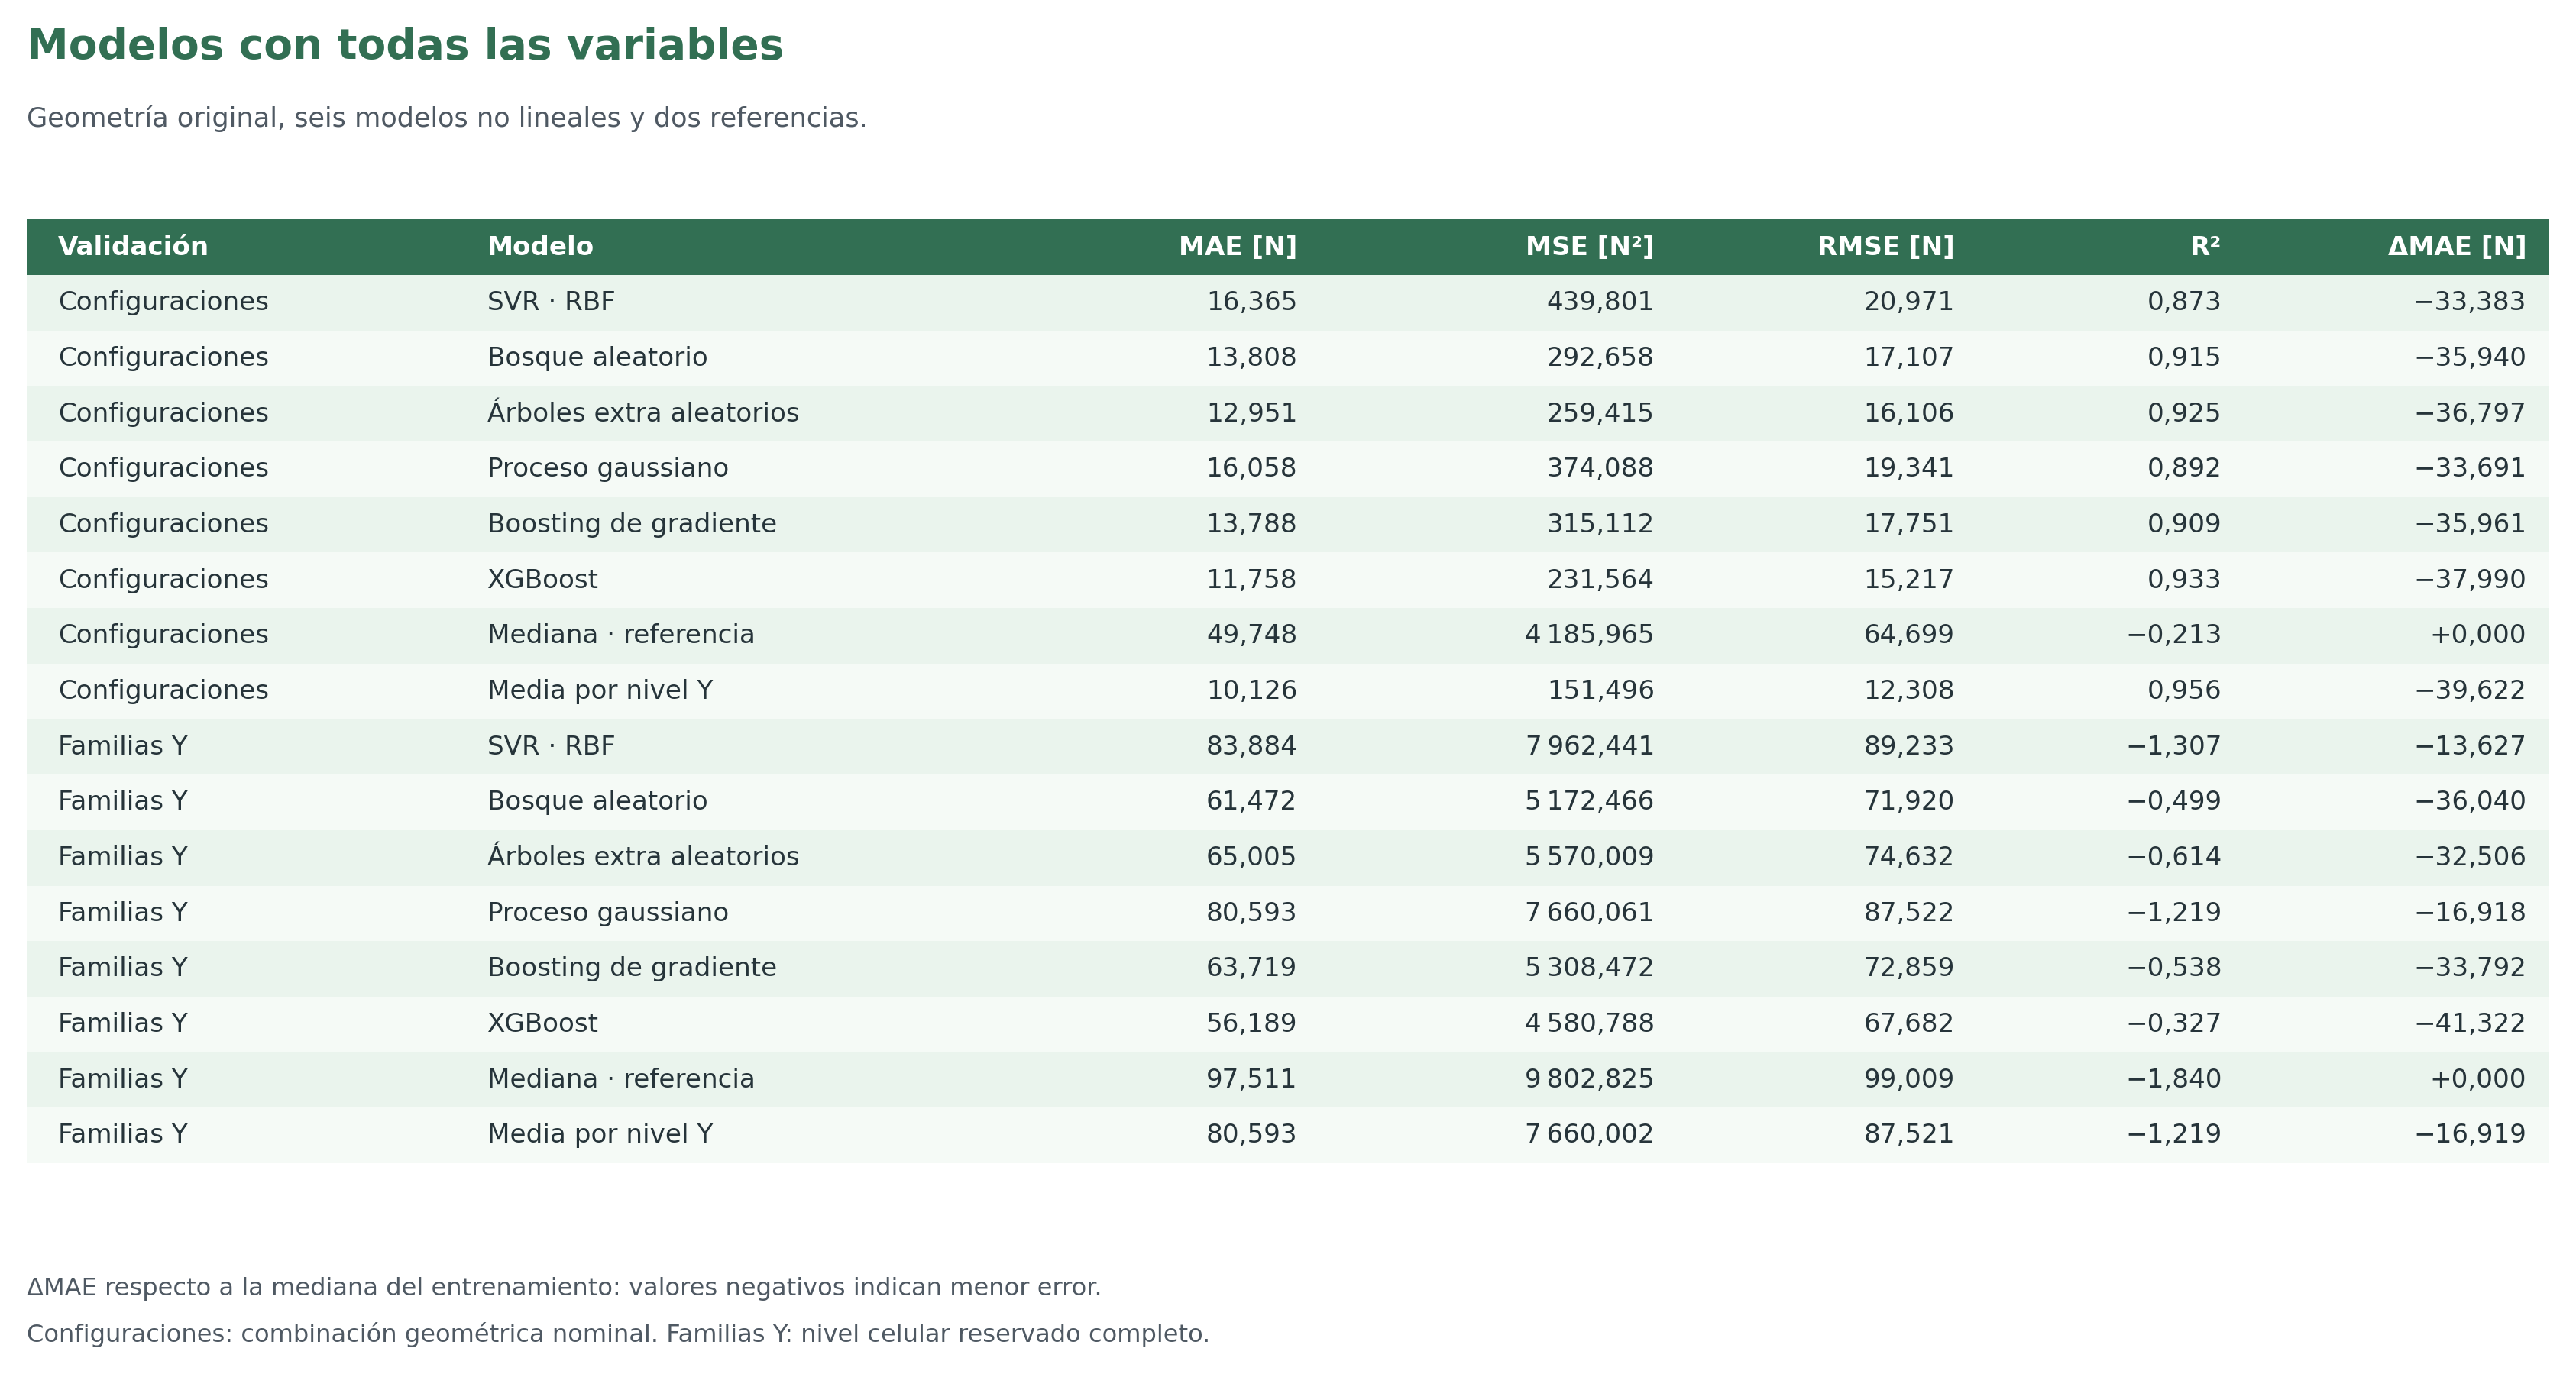

In [4]:
figura(18)
completos = metricas[metricas.conjunto.eq('todas')]
for protocolo in ['configuracion','familia']:
    g = completos[completos.protocolo.eq(protocolo)]
    rangos = f"{g.MAE_N.min():.3f}–{g.MAE_N.max():.3f}"
    ganan = g[(g.delta_MAE_vs_mediana_N<0)&(g.delta_MAE_vs_media_nivel_N<0)]
    mejor = g.loc[g.MAE_N.idxmin()]
    texto = f"En {PROTOCOLOS[protocolo].lower()}, el MAE de las seis familias se sitúa entre {rangos} N. "
    texto += f"El menor MAE observado corresponde a {MODELOS[mejor.modelo]} ({mejor.MAE_N:.3f} N). "
    texto += f"{len(ganan)} de las seis mejoran simultáneamente las dos referencias. "
    texto += 'El orden describe esta campaña; la selección posterior del mínimo no constituye una nueva evaluación independiente.'
    interpretar(texto)

## 4. Cuatro entradas seleccionadas dentro del entrenamiento

En cada entrenamiento externo se ordenan las entradas originales no constantes por el aumento medio de MAE obtenido mediante **20 permutaciones** sobre predicciones internas reservadas. Se conservan las cuatro primeras y se reajusta el mismo modelo con los hiperparámetros elegidos para todas las entradas dentro de ese entrenamiento. El desempate sigue el orden original de las columnas.

El subconjunto puede cambiar entre modelos y particiones. La cardinalidad cuatro es una condición del contraste, no una afirmación de que existan exactamente cuatro variables relevantes. Si alguna importancia interna es nula o negativa, la entrada puede conservarse para completar ese tamaño y queda registrada.

La tabla morada compara las predicciones externas del procedimiento reducido. Su última columna es **MAE con cuatro entradas menos MAE con todas las entradas**, para el mismo modelo y protocolo. La selección no utiliza la respuesta del caso externo.

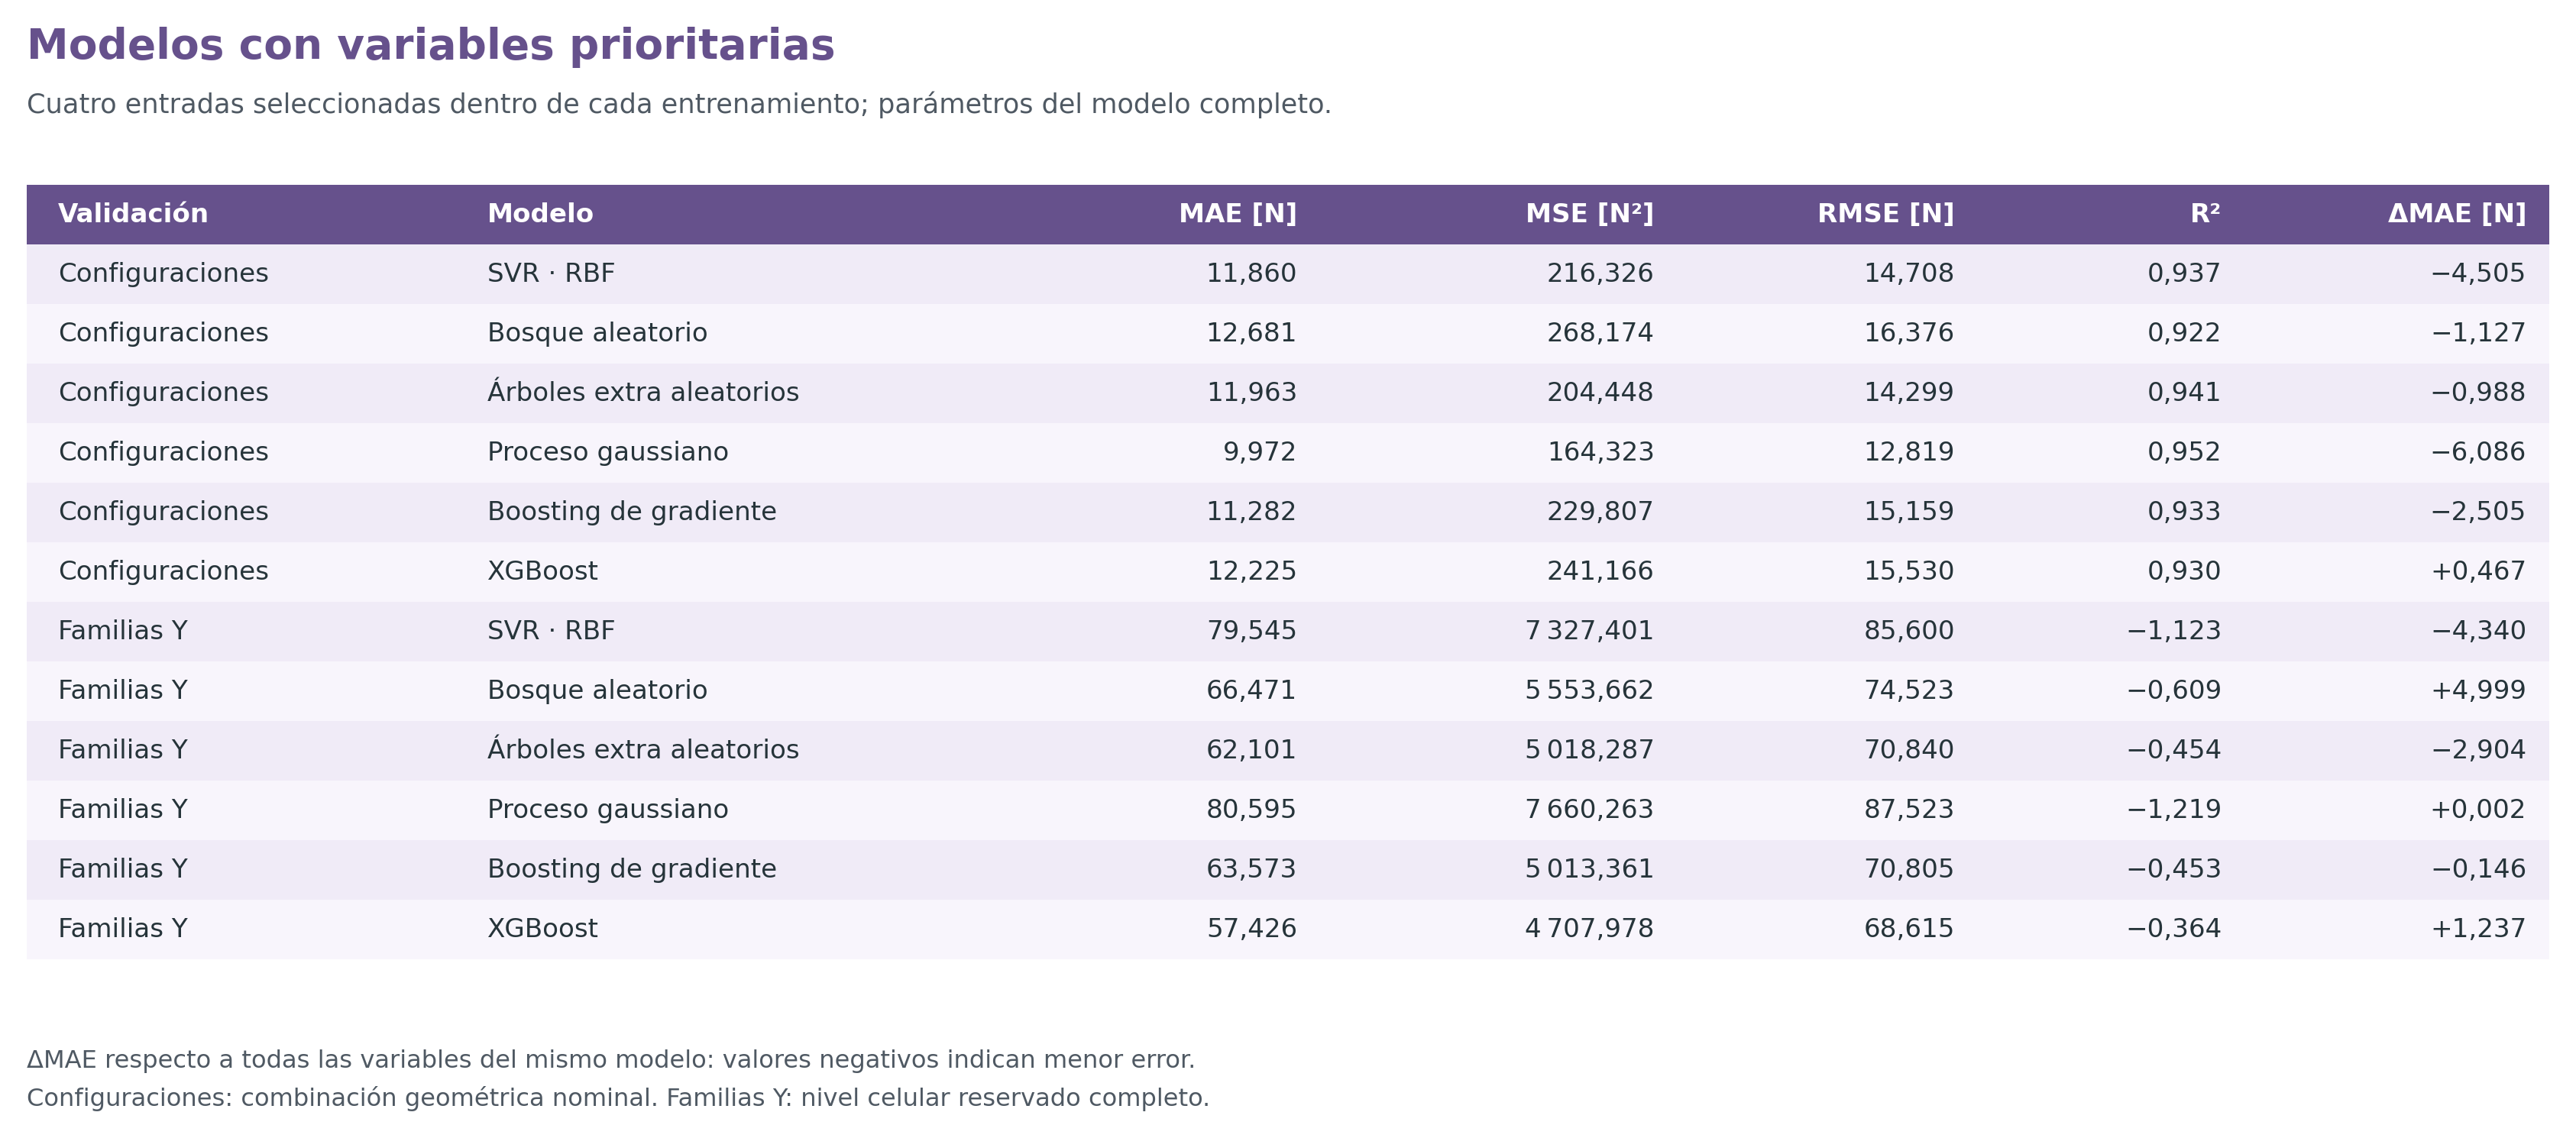

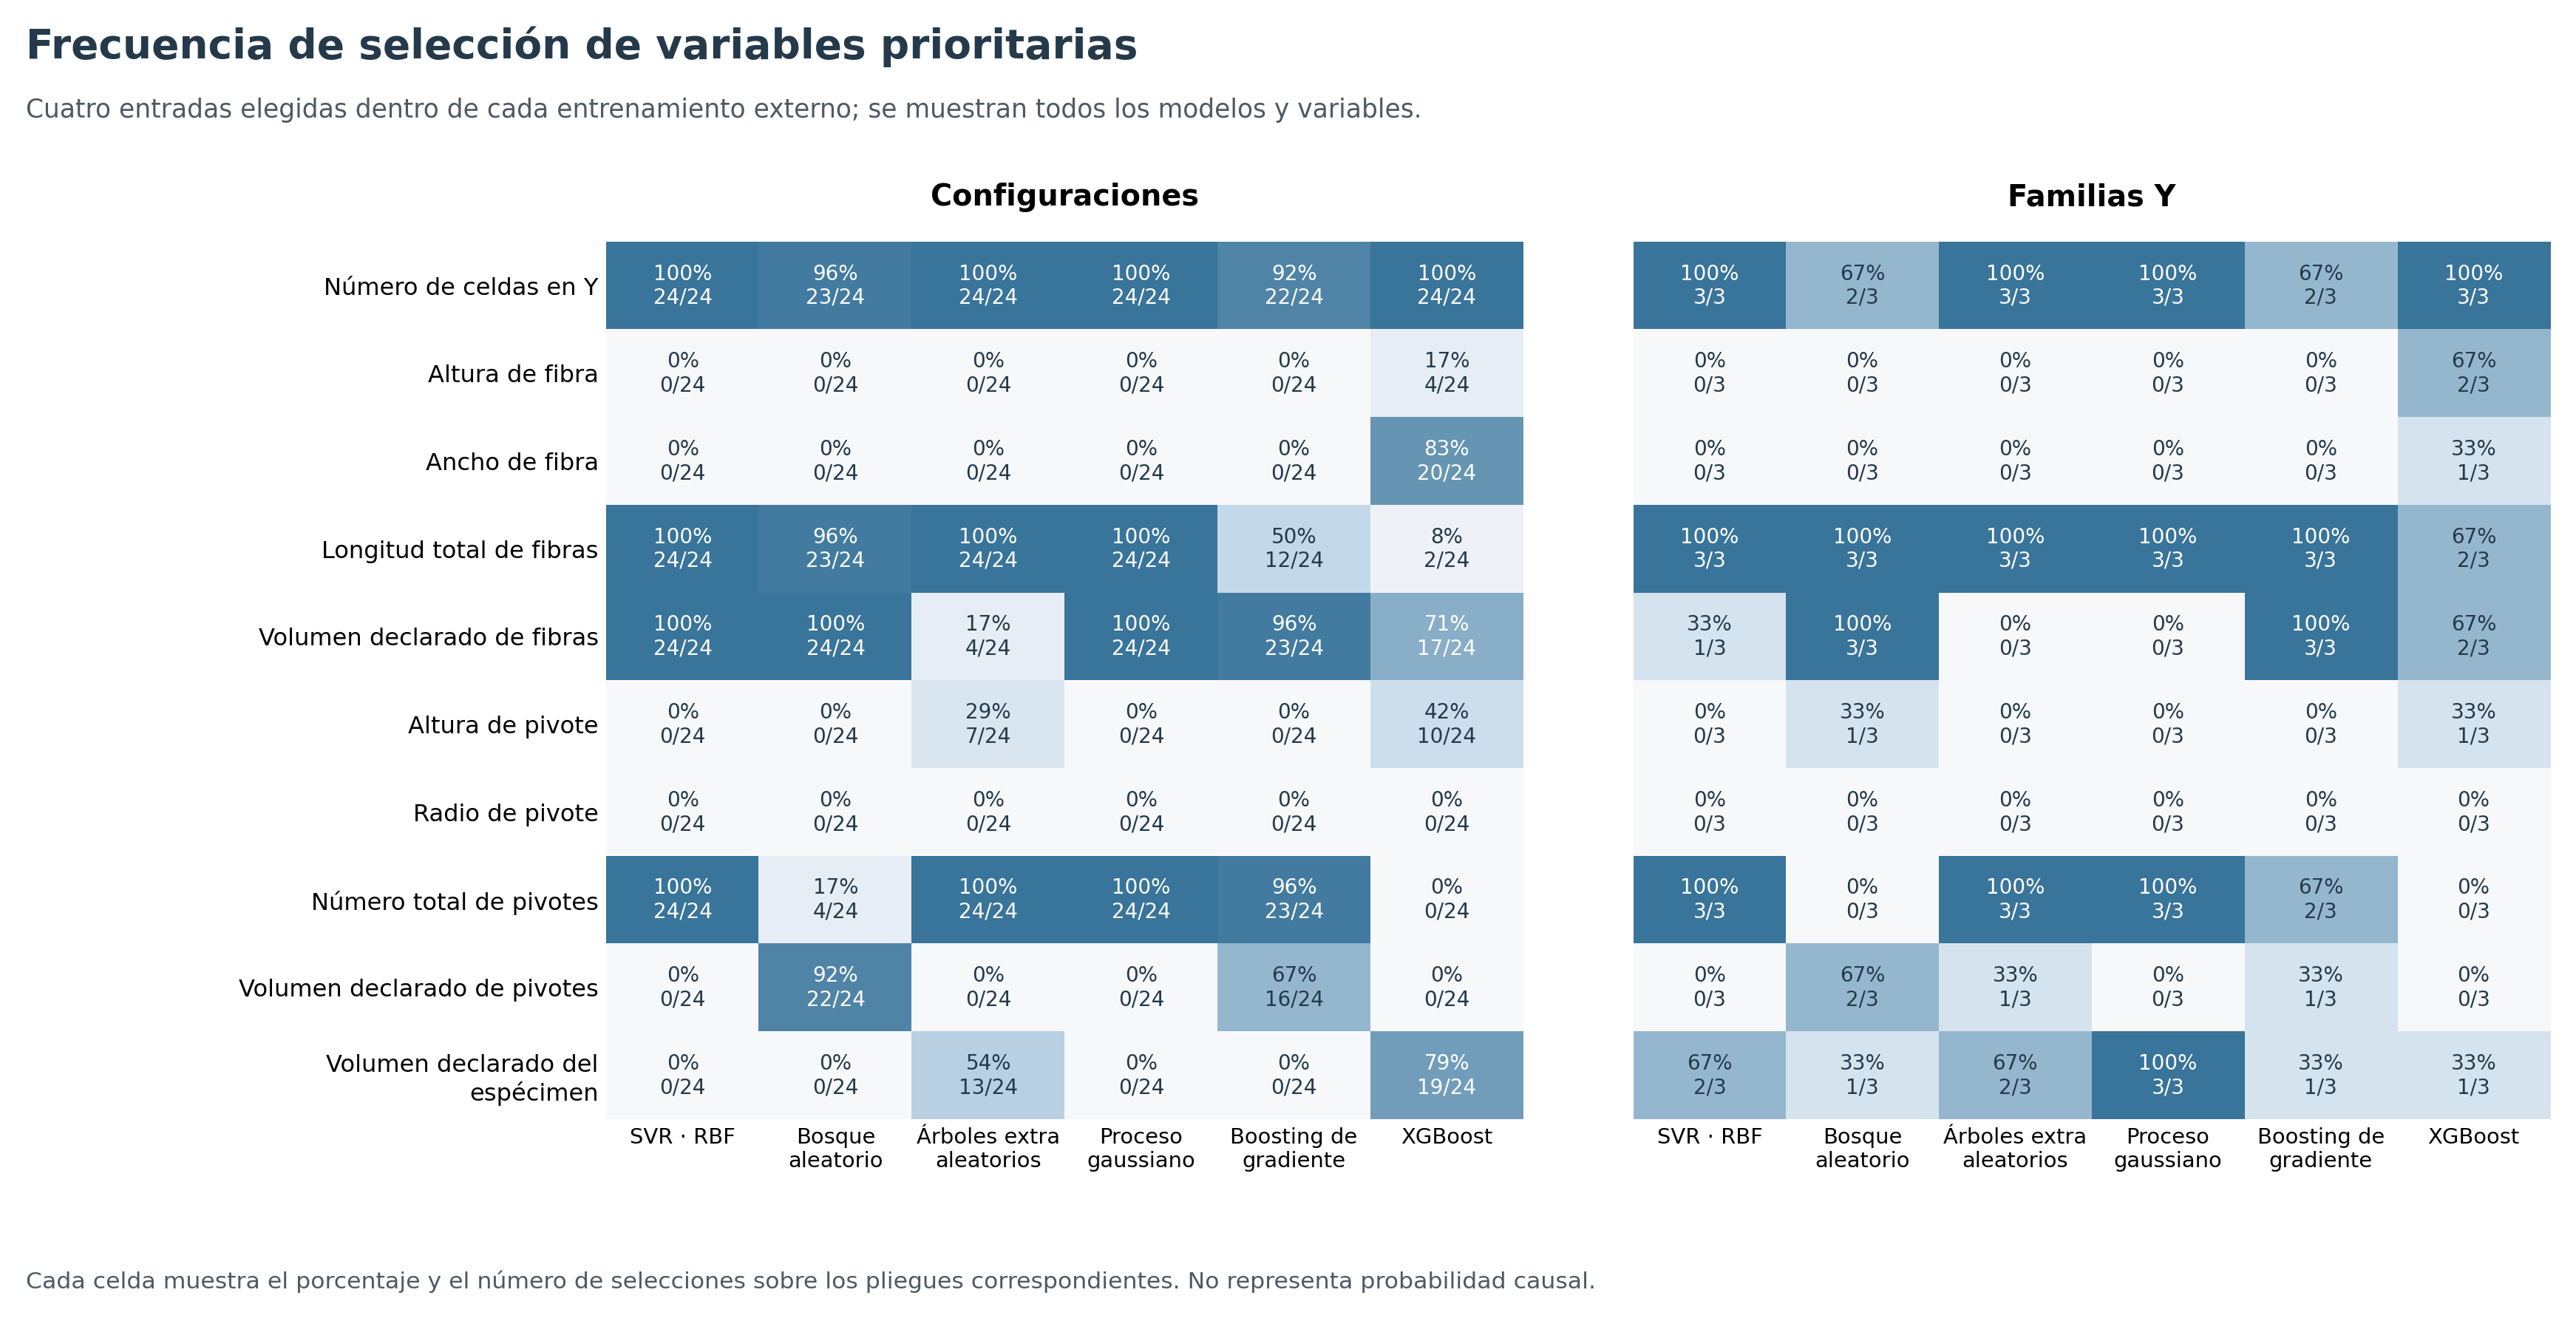

In [5]:
figura(19)
for protocolo in ['configuracion','familia']:
    g = comparacion[comparacion.protocolo.eq(protocolo)]
    mejoran = int((g.delta_MAE_reducir_N < 0).sum())
    interpretar(f"Al reservar {PROTOCOLOS[protocolo].lower()}, la selección interna reduce el MAE en {mejoran} de las seis familias. "
                'La comparación evalúa el procedimiento de selección dentro de esta campaña; una reducción pequeña del error no demuestra equivalencia estadística ni generalización satisfactoria.', '#f3edff')
for protocolo in ['configuracion','familia']:
    grupo = metricas[(metricas.protocolo==protocolo)&(metricas.conjunto=='prioritarias')&metricas.modelo.isin(MODELOS)]
    mejor = grupo.loc[grupo.MAE_N.idxmin()]
    base = metricas[(metricas.protocolo==protocolo)&(metricas.modelo=='Mediana')].iloc[0]
    interpretar(f"Con cuatro entradas y reserva de {PROTOCOLOS[protocolo].lower()}, el menor MAE observado es {mejor.MAE_N:.3f} N ({MODELOS[mejor.modelo]}). "
                f"La mediana de entrenamiento obtiene {base.MAE_N:.3f} N. El R² del primero es {mejor.R2:.3f}. "
                'Este resultado se interpreta dentro del protocolo evaluado y no identifica un ganador universal.', '#f3edff')
figura(4)

## 5. Importancia por permutación repetida

Para cada modelo ya ajustado se calcula **ΔMAE = MAE con entradas perturbadas − MAE original**. La perturbación modifica únicamente las entradas; la respuesta observada y el modelo permanecen fijos. Se realizan **100 repeticiones**, con las mismas asignaciones de donantes para los modelos, subconjuntos y bloques.

La mayoría de las reservas nominales contiene una sola observación. Por ello, se aplica **permutación marginal cruzada** sobre la matriz de casos con predicción externa: cada receptor se evalúa con el modelo que lo excluyó y recibe los valores de un donante de esa matriz. El donante puede pertenecer al entrenamiento del modelo receptor; no se afirma disponer de un conjunto independiente común para todos los modelos. La respuesta del donante no interviene en la perturbación.

Un ΔMAE positivo indica deterioro bajo esa perturbación. Un valor negativo indica que el error disminuyó y se conserva con su signo. Valores pequeños frente a su dispersión ofrecen una evidencia débil de dependencia predictiva. Las figuras muestran la media y barras de ±1 desviación estándar entre permutaciones. Los archivos también conservan los percentiles empíricos 5 y 95. Ambos resúmenes describen variabilidad de Monte Carlo, no intervalos de confianza poblacionales ni incertidumbre por reentrenamiento.

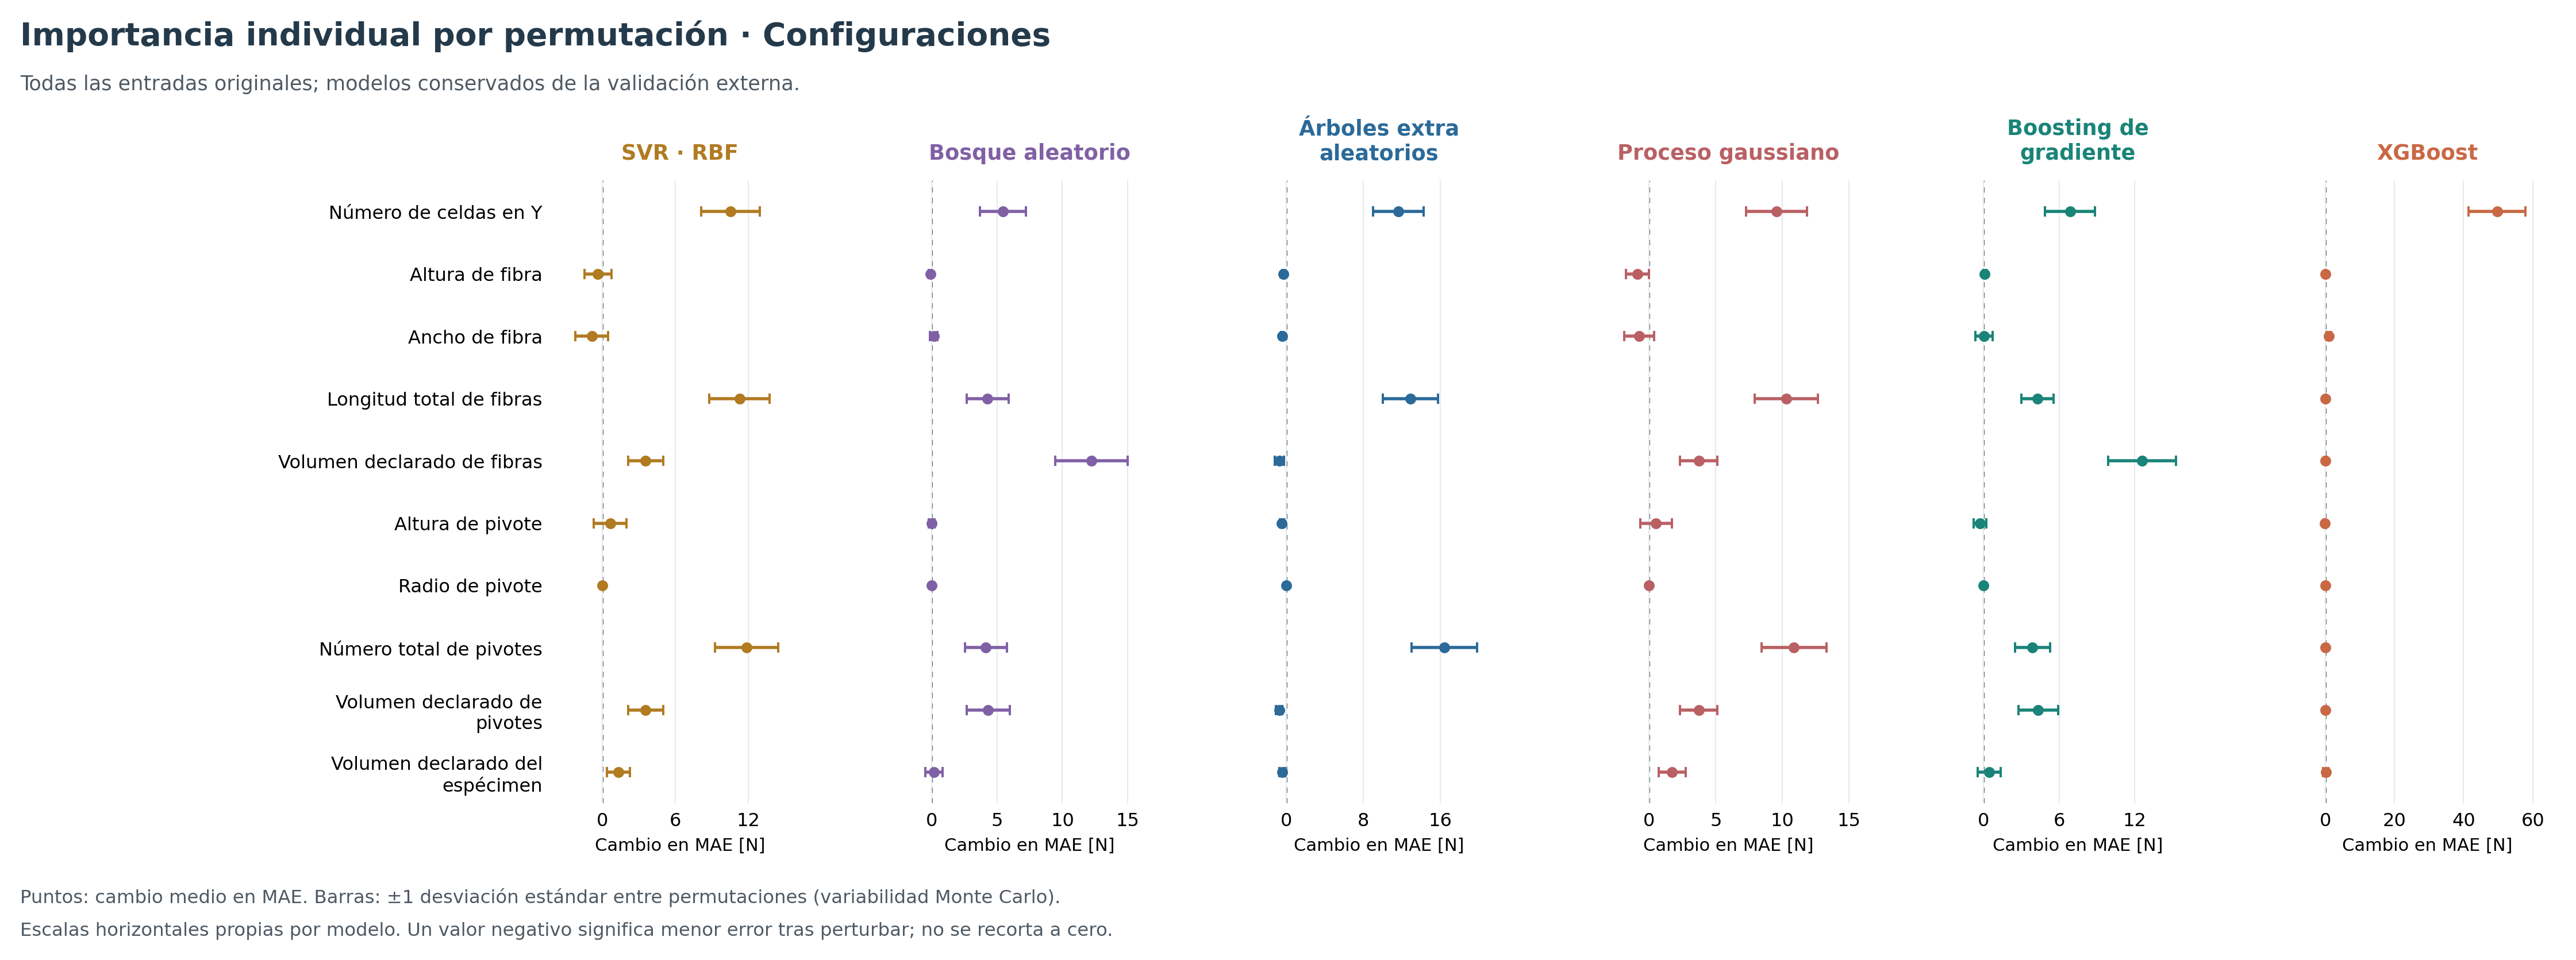

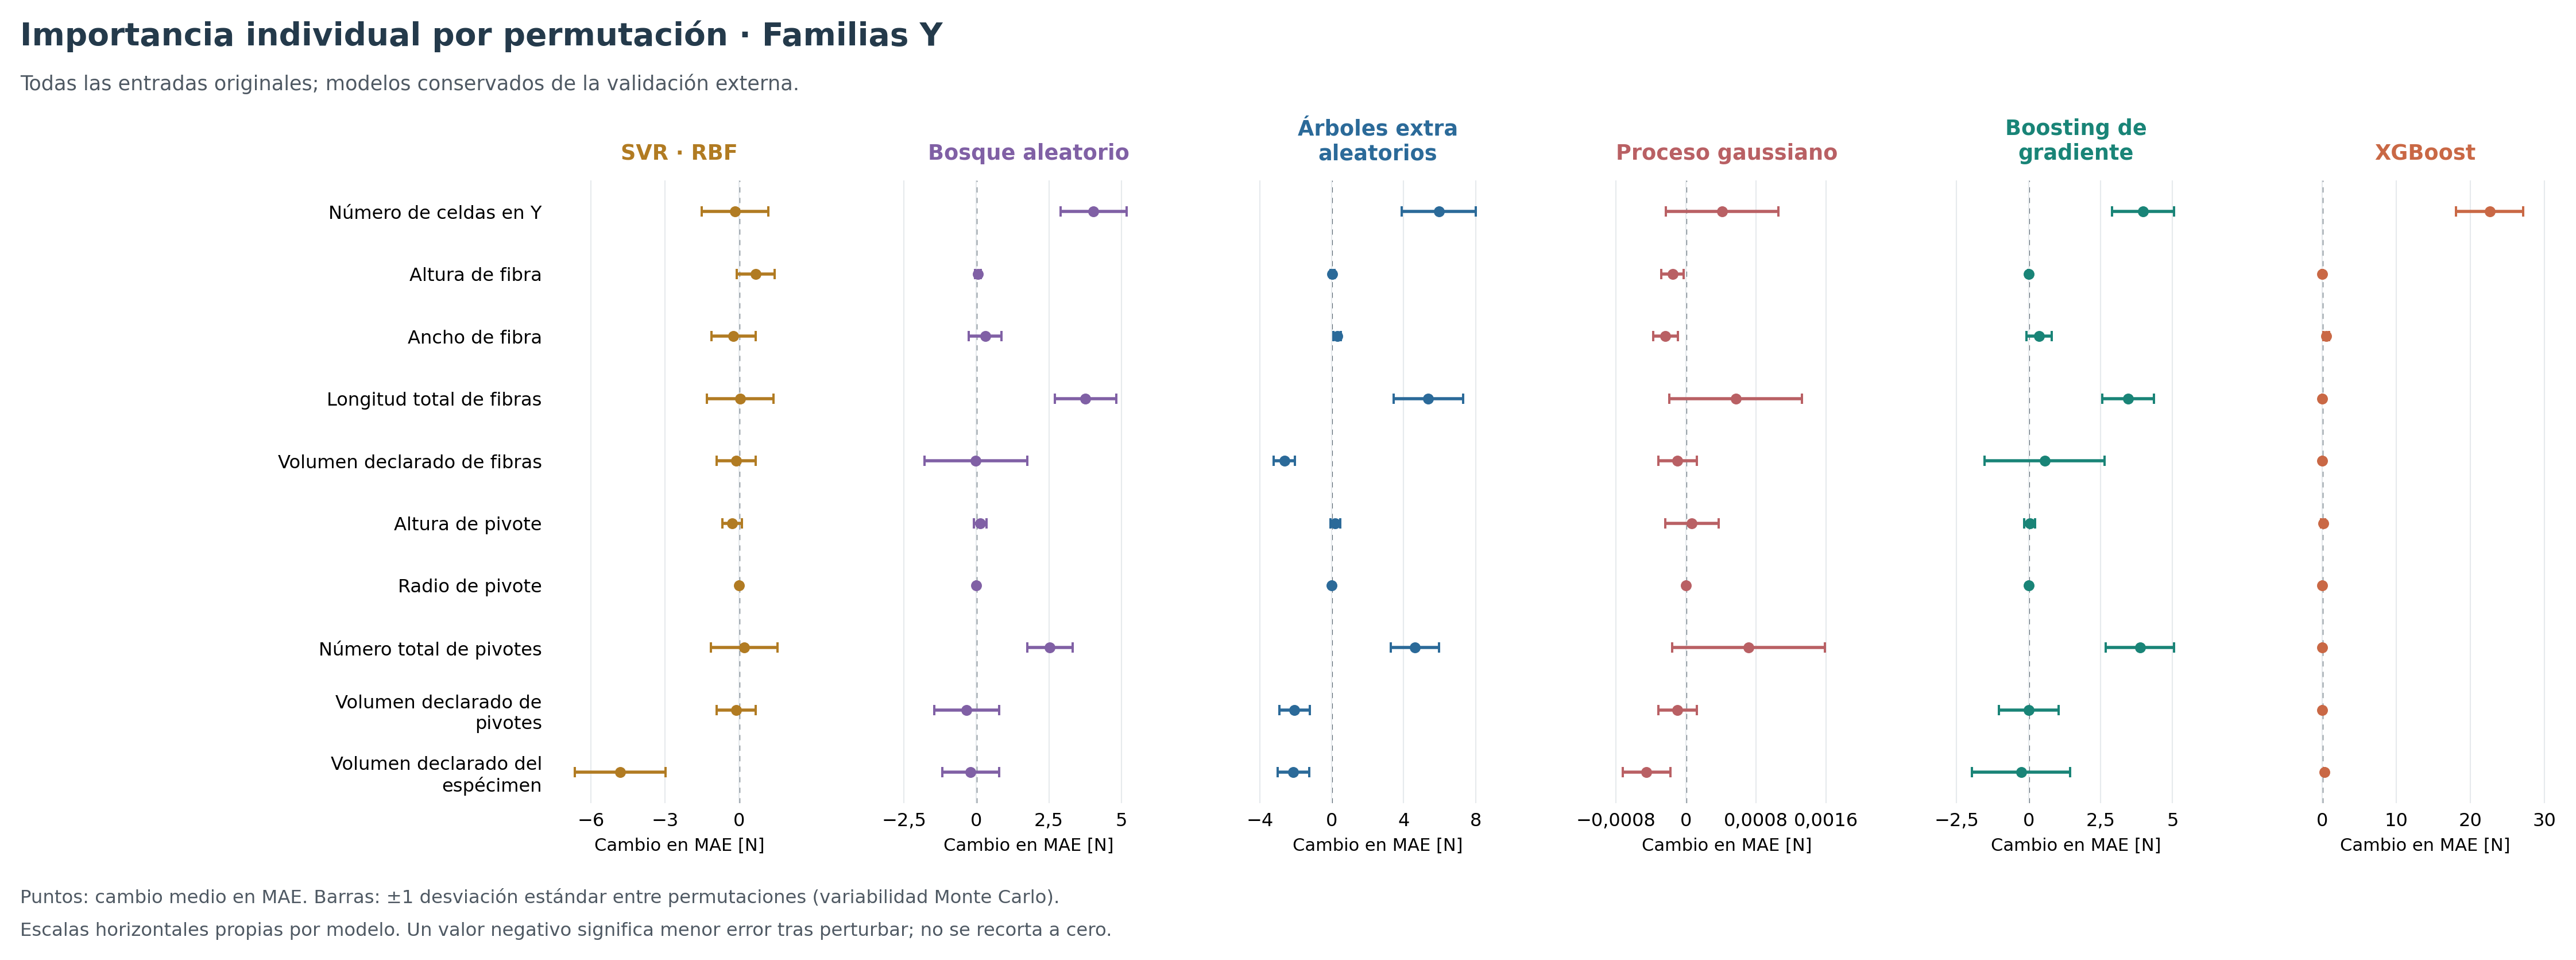

In [6]:
importancias = tabla('importancia_resumen')
figura(1)
figura(2)
pequenas = importancias[(importancias.conjunto=='todas') & (importancias.tipo=='variable')].copy()
pequenas['cruza_cero'] = (pequenas.p05_N<=0)&(pequenas.p95_N>=0)
negativas = int((pequenas.delta_MAE_media_N<0).sum())
ambiguas = int(pequenas.cruza_cero.sum())
interpretar(f"Entre las evaluaciones individuales de los modelos completos y los dos protocolos, {negativas} tienen media negativa y {ambiguas} presentan un rango de percentiles que incluye cero. "
            'Se mantienen estos resultados: no se convierten en cero ni se interpretan como ausencia demostrada de función mecánica. El radio constante no permite estimar sensibilidad a radios diferentes.')

### 5.1 Dependencias entre entradas y permutación de bloques

Se declaran los bloques antes de calcular las importancias: arquitectura (celdas, longitud de fibras y número de pivotes), sección de fibra (altura y base), volúmenes (fibras, pivotes y espécimen) y dimensiones del pivote (altura y radio). También se perturban conjuntamente arquitectura y volúmenes.

Todas las columnas de un bloque se sustituyen con valores de la **misma fila donante**, conservando sus relaciones internas. Las relaciones entre bloques pueden romperse y generar combinaciones no ensayadas. La importancia grupal no se obtiene sumando las importancias individuales ni identifica un efecto físico aislado.

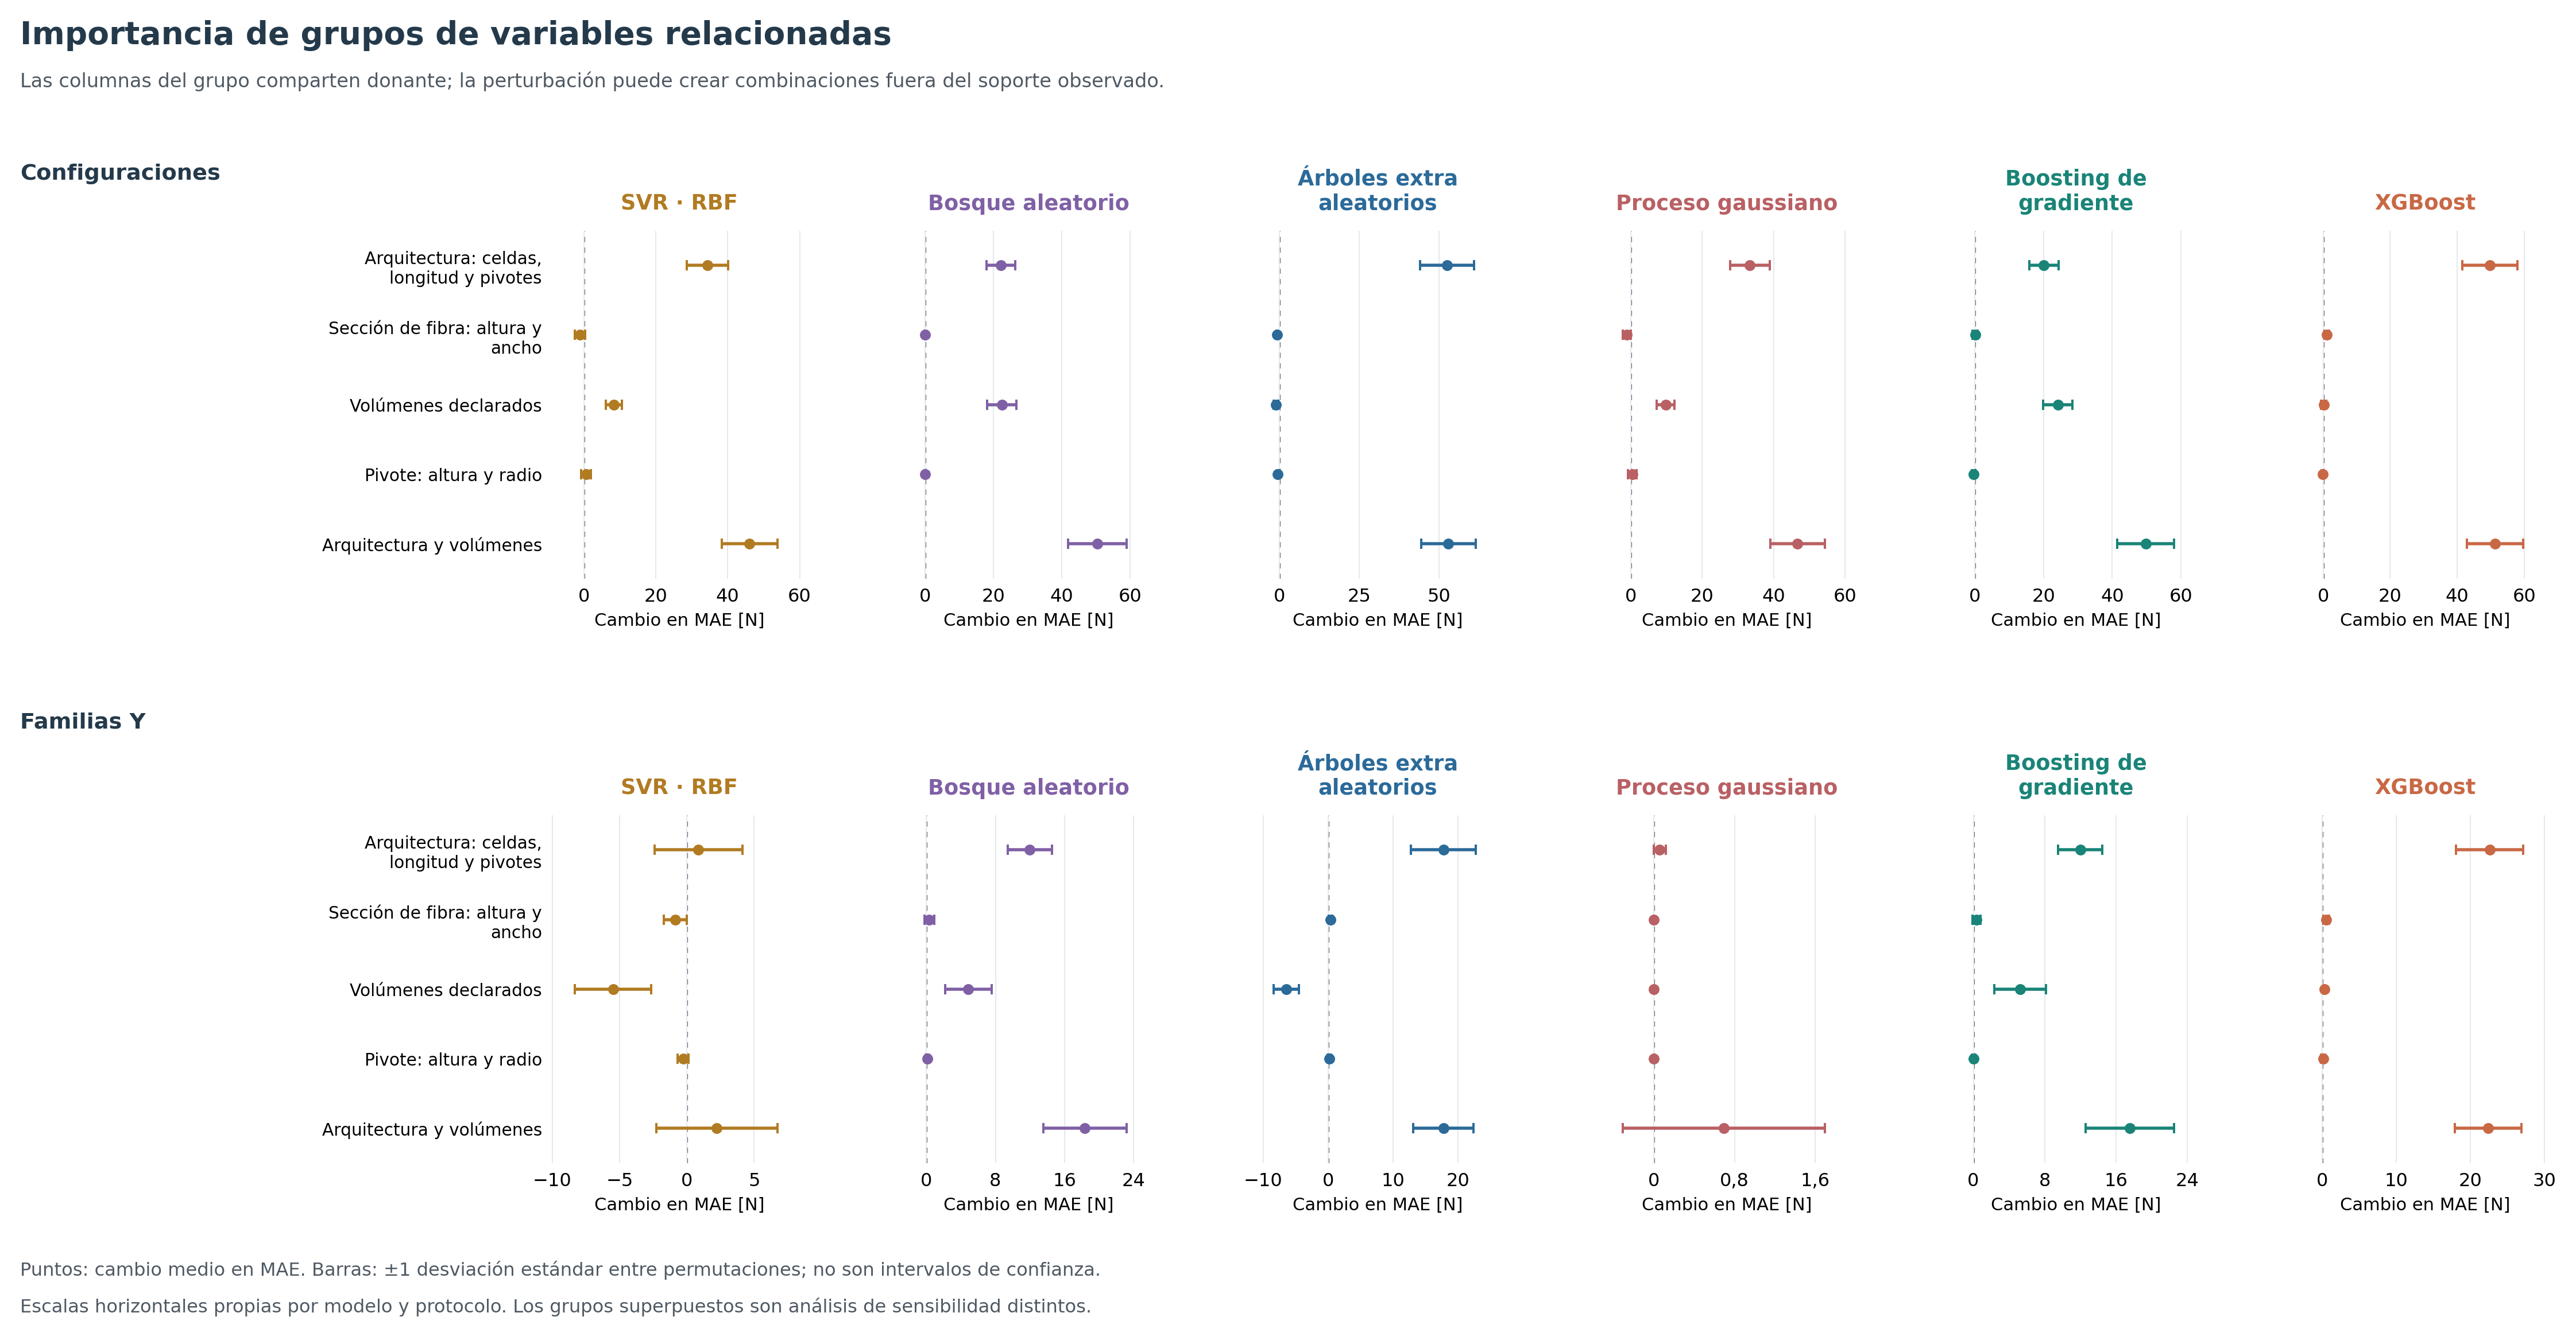

In [7]:
figura(3)
seleccion = tabla('seleccion_variables')
escogidas = seleccion[seleccion.seleccionada.astype(bool)]
no_positivas = int((escogidas.PFI_interna_media_N<=0).sum())
interpretar(f"Se registran {no_positivas} selecciones con importancia interna no positiva. "
            'La frecuencia de selección describe cuán a menudo se conserva una entrada bajo esta regla y estos entrenamientos; no es una probabilidad de relevancia física. '
            'La dependencia entre descriptores puede repartir u ocultar información en las importancias individuales.')

### 5.2 Ablación del bloque de arquitectura y volúmenes

Se retiran conjuntamente número de celdas en Y, longitud total de fibras, número total de pivotes y los tres volúmenes declarados. Cada modelo se **vuelve a ajustar** con las entradas restantes y los hiperparámetros elegidos para el modelo completo en el mismo entrenamiento externo, manteniendo las particiones externas.

La diferencia **MAE sin el bloque − MAE completo** responde a la utilidad del bloque cuando el modelo puede adaptarse a su ausencia. La permutación evalúa el modelo ya entrenado. Ambas cantidades pueden discrepar; ninguna demuestra causalidad.

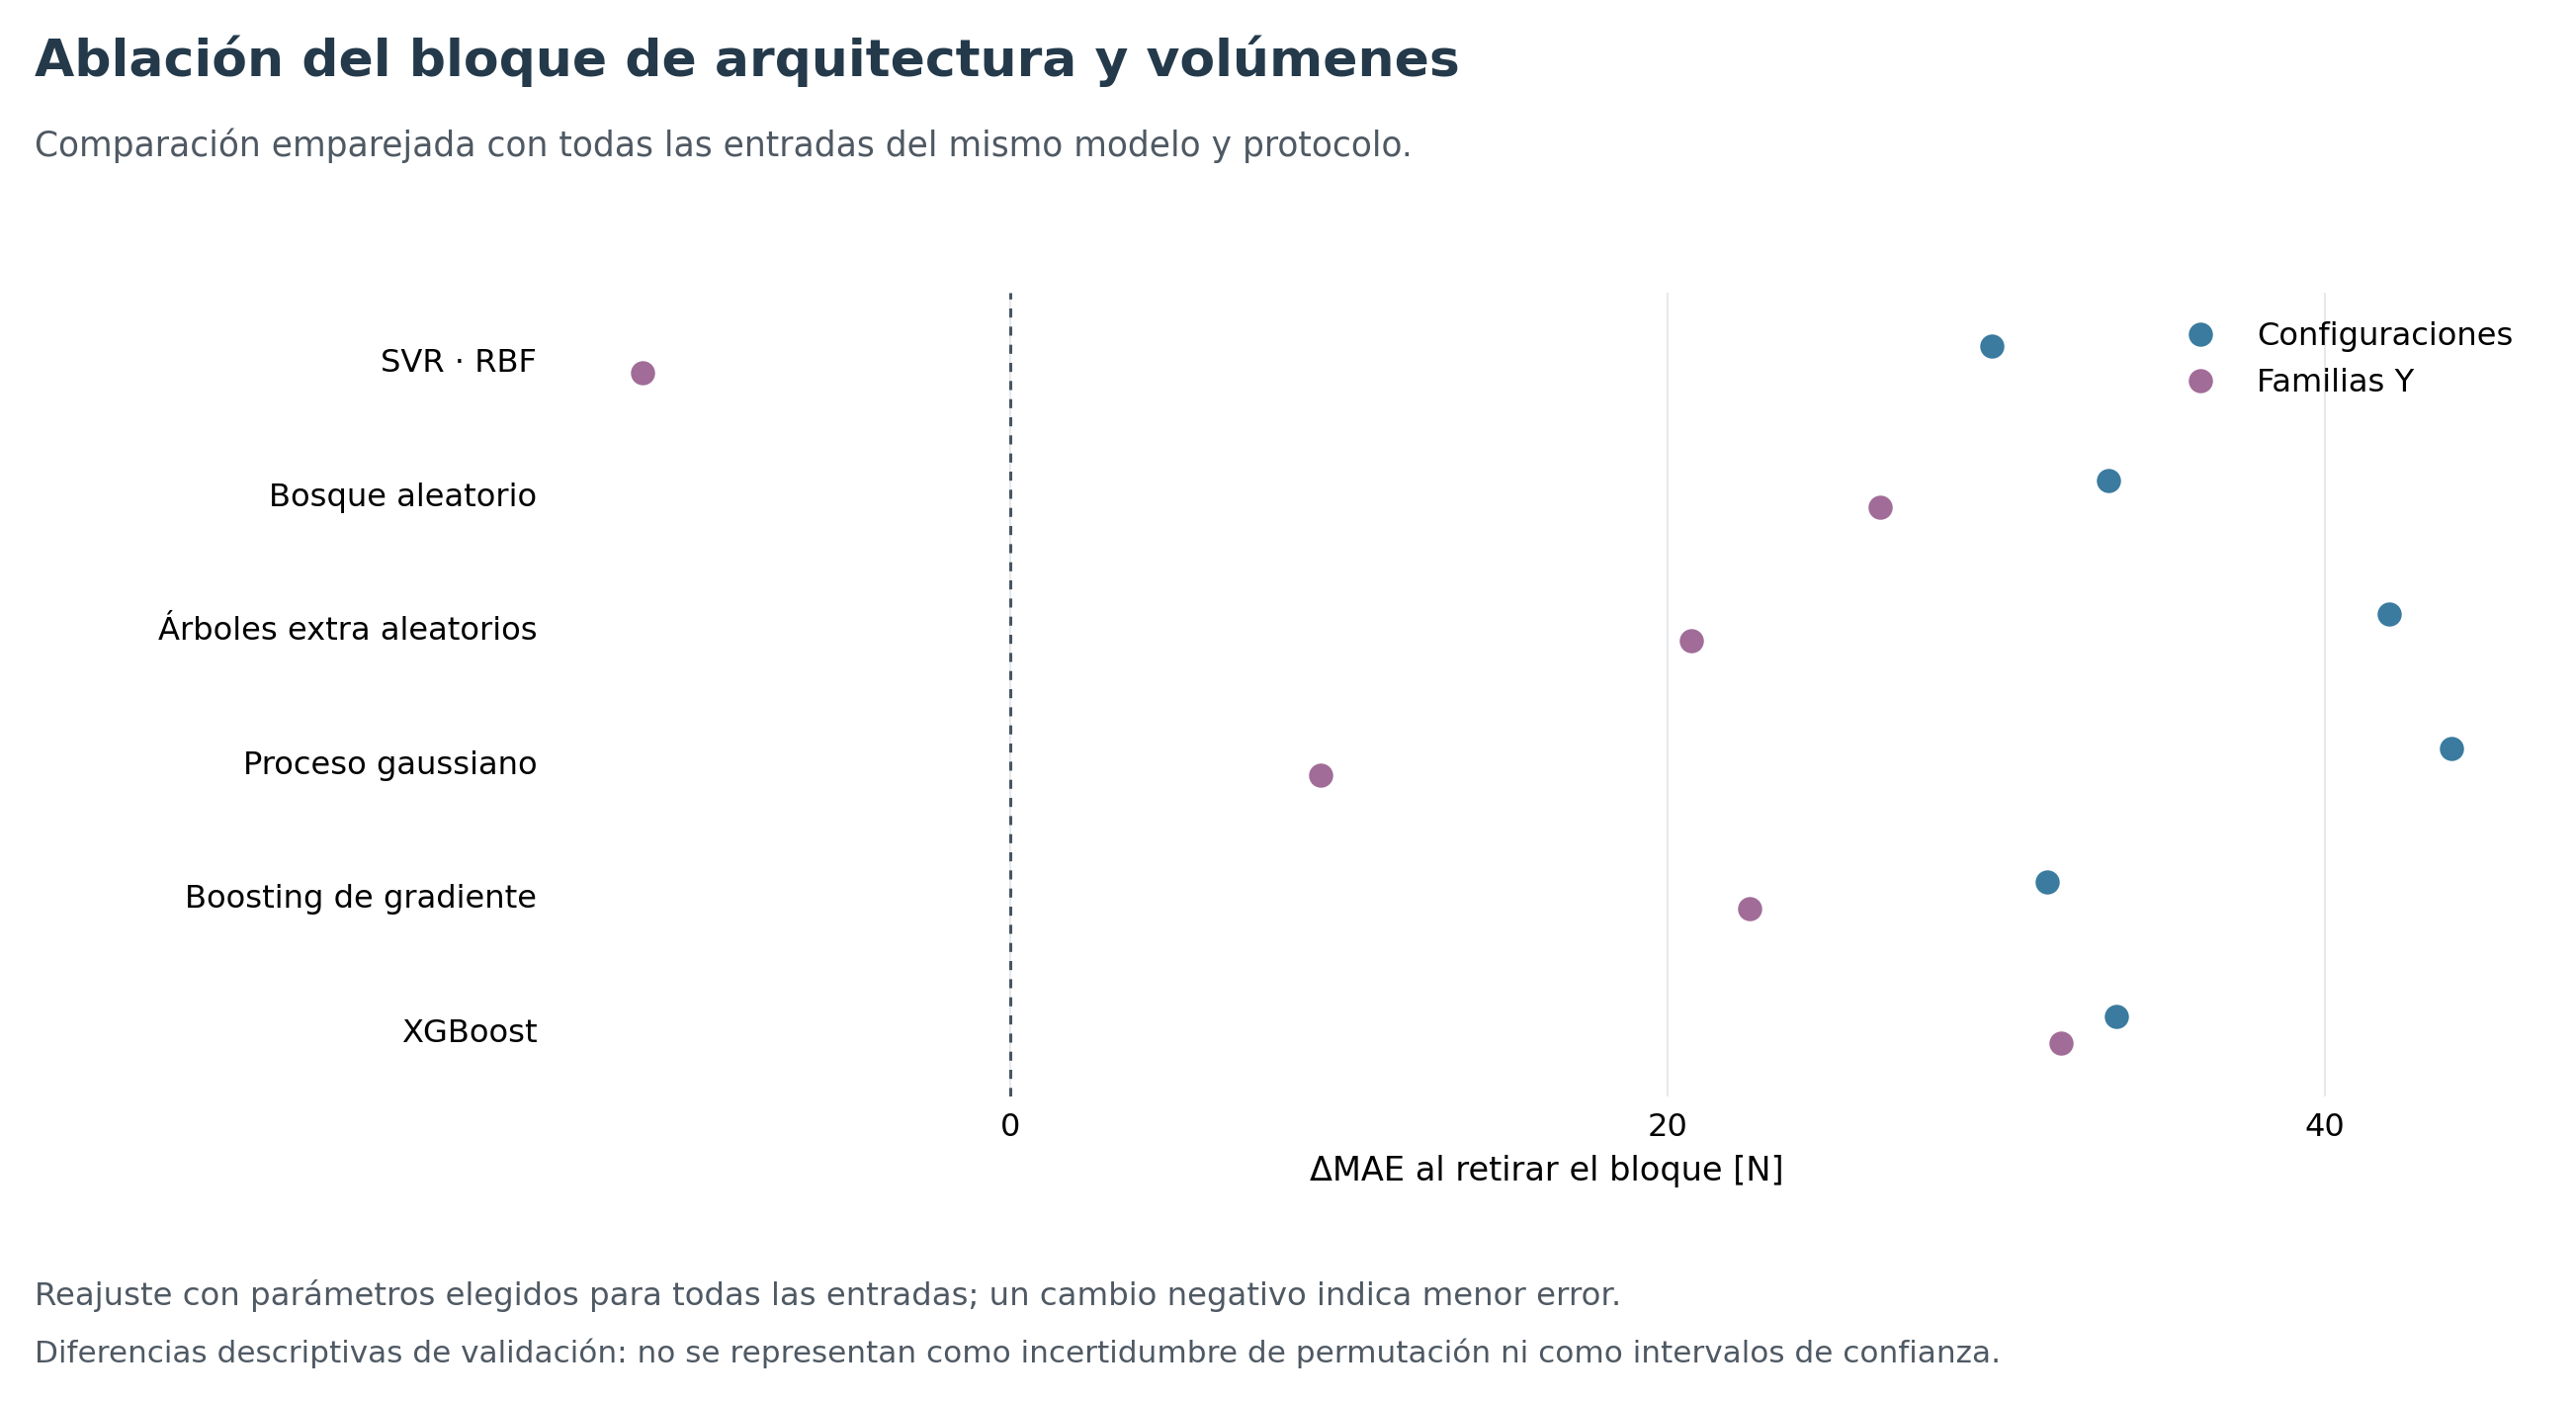

In [8]:
figura(5)

## 6. Atribución SHAP de un ensamble de árboles

Se explica el ensamble de árboles que obtuvo el menor MAE descriptivo con todas las entradas al reservar configuraciones. Cada caso se analiza con el modelo del pliegue que no lo utilizó para ajustar sus parámetros. `TreeExplainer` emplea como referencia solo las entradas del entrenamiento correspondiente y atribuye la predicción en newtons. En cada caso, el valor de referencia más la suma de contribuciones SHAP debe reconstruir la predicción del modelo. Esta igualdad comprueba el cálculo de atribuciones; no significa que la predicción coincida con la fuerza experimental.

La magnitud media absoluta resume cuánto desplaza cada variable las predicciones respecto de la referencia. El signo local indica si una variable eleva o reduce **esa predicción**, dadas las demás entradas y el supuesto de perturbación del explicador. Los descriptores geométricos correlacionados pueden repartirse la atribución y la importancia individual no constituye una prueba causal.

C:\Users\MELISSA\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


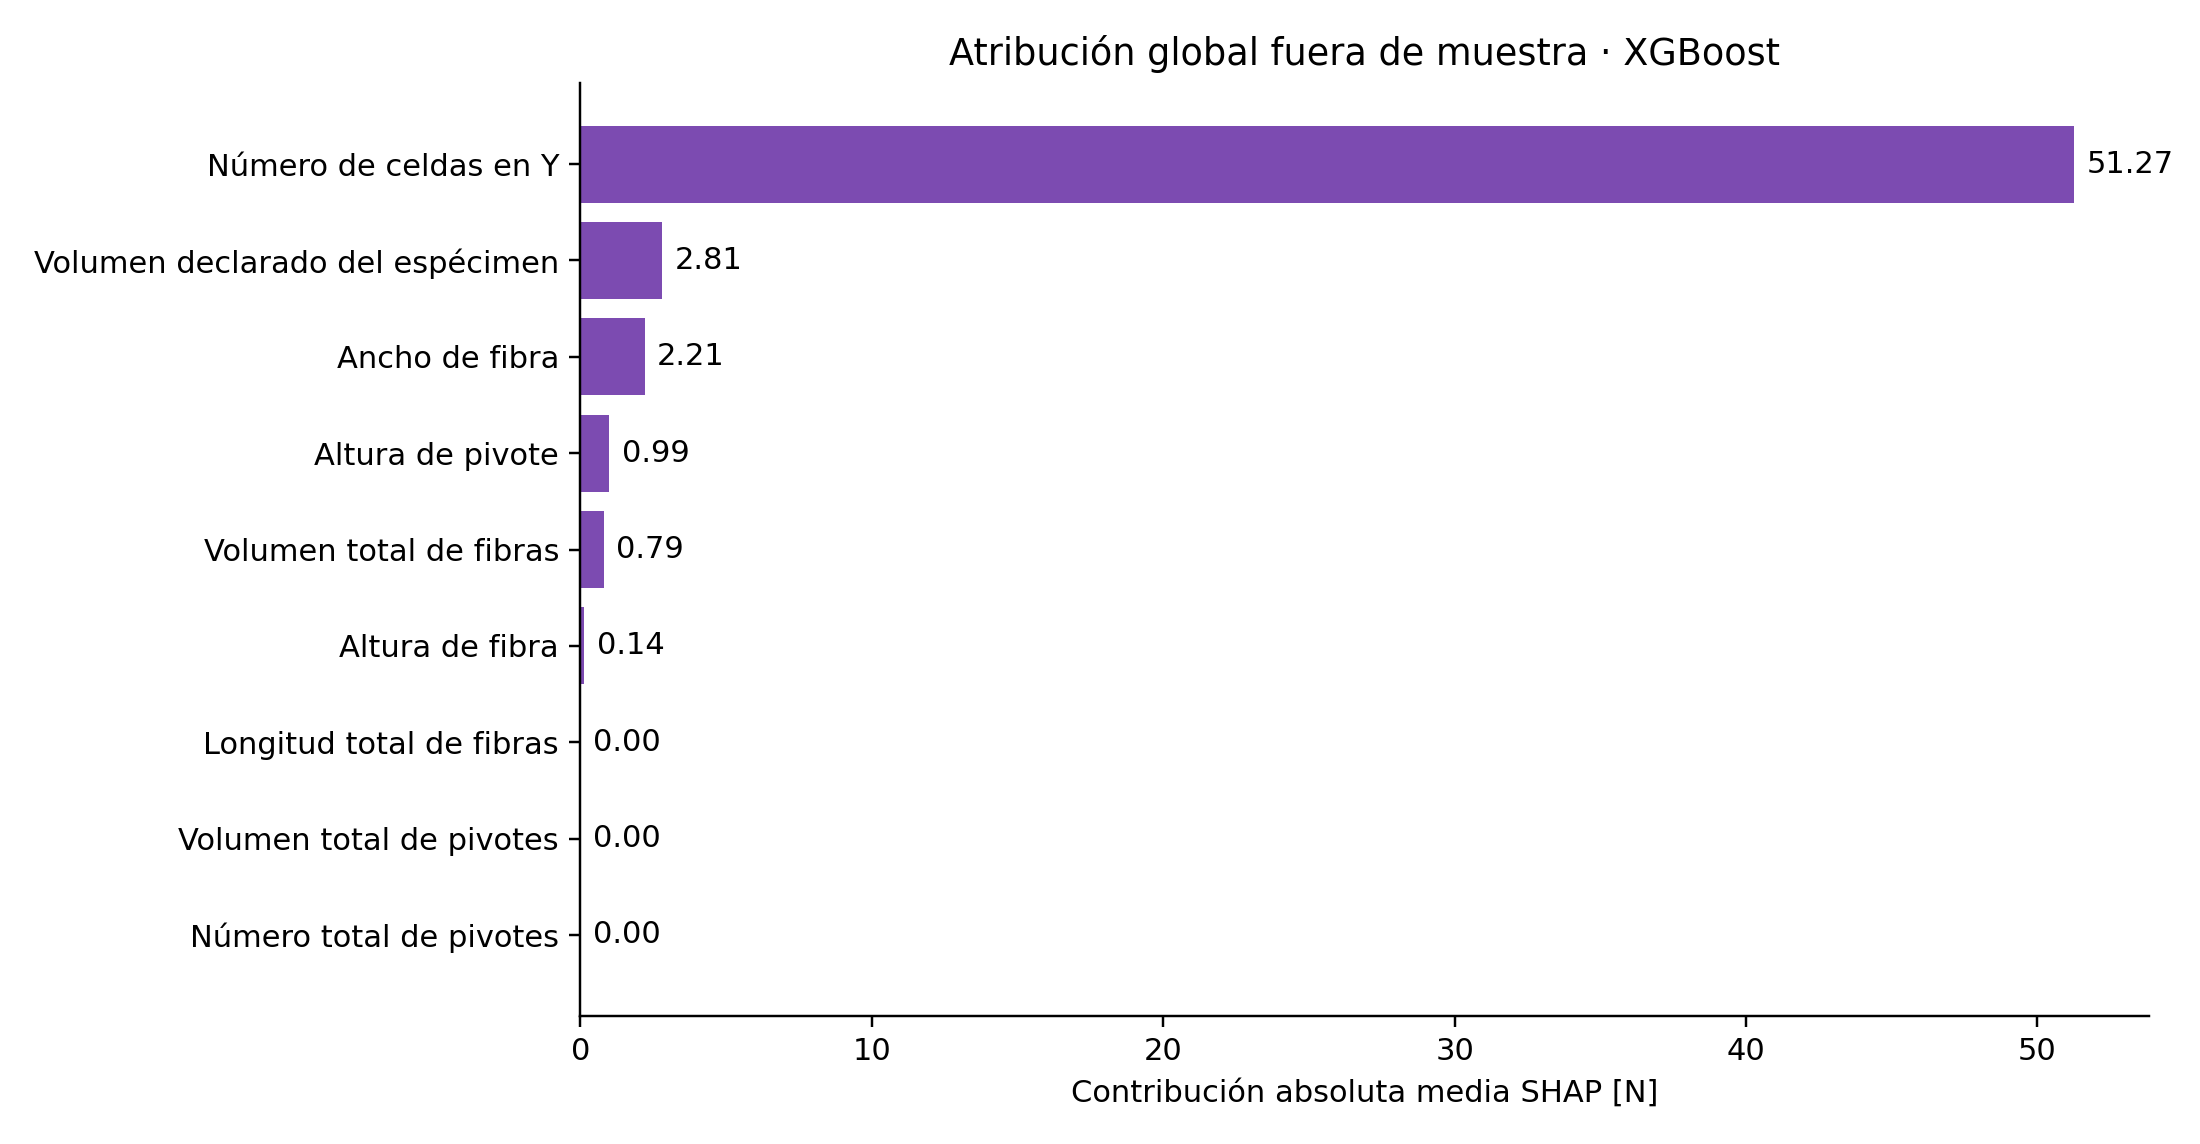

,Variable geométrica,SHAP absoluto medio [N],Aumento medio de MAE al permutar [N]
0,Número de celdas en Y,51.271,49.699
1,Volumen declarado del espécimen,2.815,0.153
2,Ancho de fibra,2.212,1.057
3,Altura de pivote,0.990,-0.190
4,Volumen total de fibras,0.793,0.095
5,Altura de fibra,0.135,-0.013
6,Longitud total de fibras,0.000,0.000
7,Volumen total de pivotes,0.000,0.000
8,Número total de pivotes,0.000,0.000


In [9]:
from src.shap_no_lineal import run as ejecutar_shap
shap_meta = ejecutar_shap(ROOT, OUT)
shap_global = tabla('shap_global')
shap_casos = tabla('shap_casos')
shap_oof = tabla('shap_oof')
shap_estabilidad = tabla('shap_estabilidad')
assert shap_casos.error_reconstruccion_N.max() < 1e-4
figura(20)
comparacion_atribuciones = shap_global.merge(
    importancias[(importancias.protocolo=='configuracion') &
                 (importancias.conjunto=='todas') &
                 (importancias.tipo=='variable') &
                 (importancias.modelo==shap_meta['modelo_explicado'])][['variable_grupo','delta_MAE_media_N']],
    left_on='variable', right_on='variable_grupo', how='left', validate='one_to_one')
assert comparacion_atribuciones.delta_MAE_media_N.notna().all()
display(comparacion_atribuciones[['nombre','SHAP_abs_medio_N','delta_MAE_media_N']].head(9)
        .rename(columns={'nombre':'Variable geométrica',
                         'SHAP_abs_medio_N':'SHAP absoluto medio [N]',
                         'delta_MAE_media_N':'Aumento medio de MAE al permutar [N]'})
        .round(3))
principal = comparacion_atribuciones.iloc[0]
interpretar(f"En {MODELOS[shap_meta['modelo_explicado']]}, {principal.nombre.lower()} tiene la mayor atribución absoluta media fuera de muestra ({principal.SHAP_abs_medio_N:.3f} N). "
            f"Su cambio medio de MAE bajo permutación es {principal.delta_MAE_media_N:+.3f} N. "
            'SHAP describe la contribución al cálculo del modelo; la permutación mide cuánto cambia el error al perturbar la entrada. Sus valores no tienen por qué coincidir.')
if principal.variable == 'n_cells_Y':
    r_pivotes = frame.n_cells_Y.corr(frame.Pivot_total_number)
    r_longitud = frame.n_cells_Y.corr(frame.Fiber_total_length)
    interpretar(f"El número de celdas en Y resume la arquitectura: su correlación con el número de pivotes es {r_pivotes:.3f} y con la longitud total de fibras, {r_longitud:.3f}. "
                'La atribución dominante puede concentrar información compartida por estos descriptores. Este patrón predictivo no identifica cuál componente controla físicamente la primera rotura, y debe leerse junto al error al reservar familias completas.', '#f3edff')

### 6.1 Un caso con error elevado y estabilidad entre particiones

La explicación local se elige por el mayor error absoluto de las predicciones externas, para examinar también un resultado desfavorable. La figura representa contribuciones positivas y negativas alrededor del valor de referencia; no es un gráfico waterfall. La estabilidad se resume como la proporción de particiones en las que cada entrada ocupa uno de los tres primeros rangos de atribución absoluta. Con particiones pequeñas, este rango puede cambiar por una sola observación.

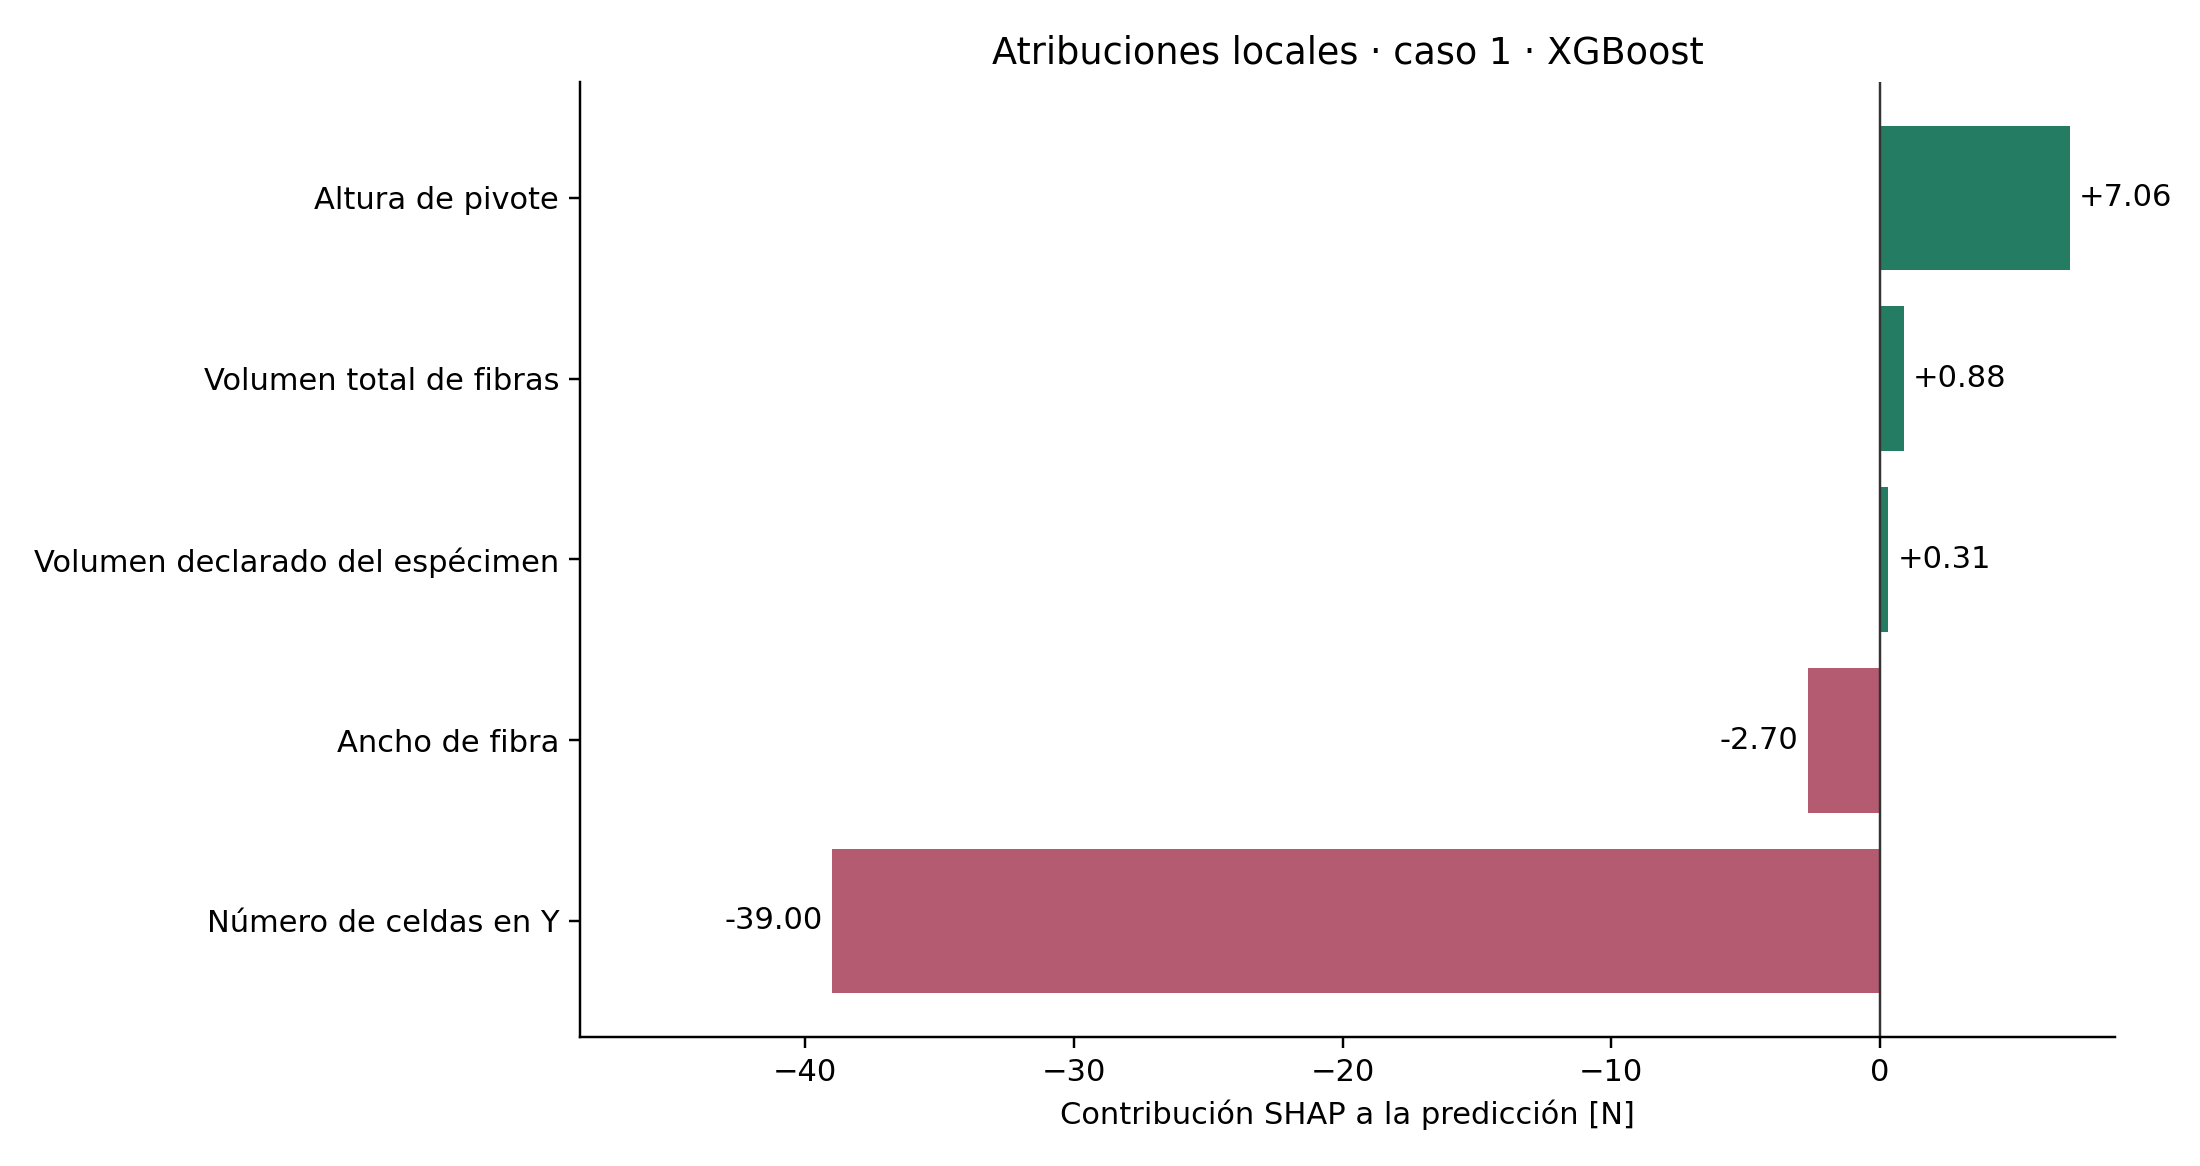

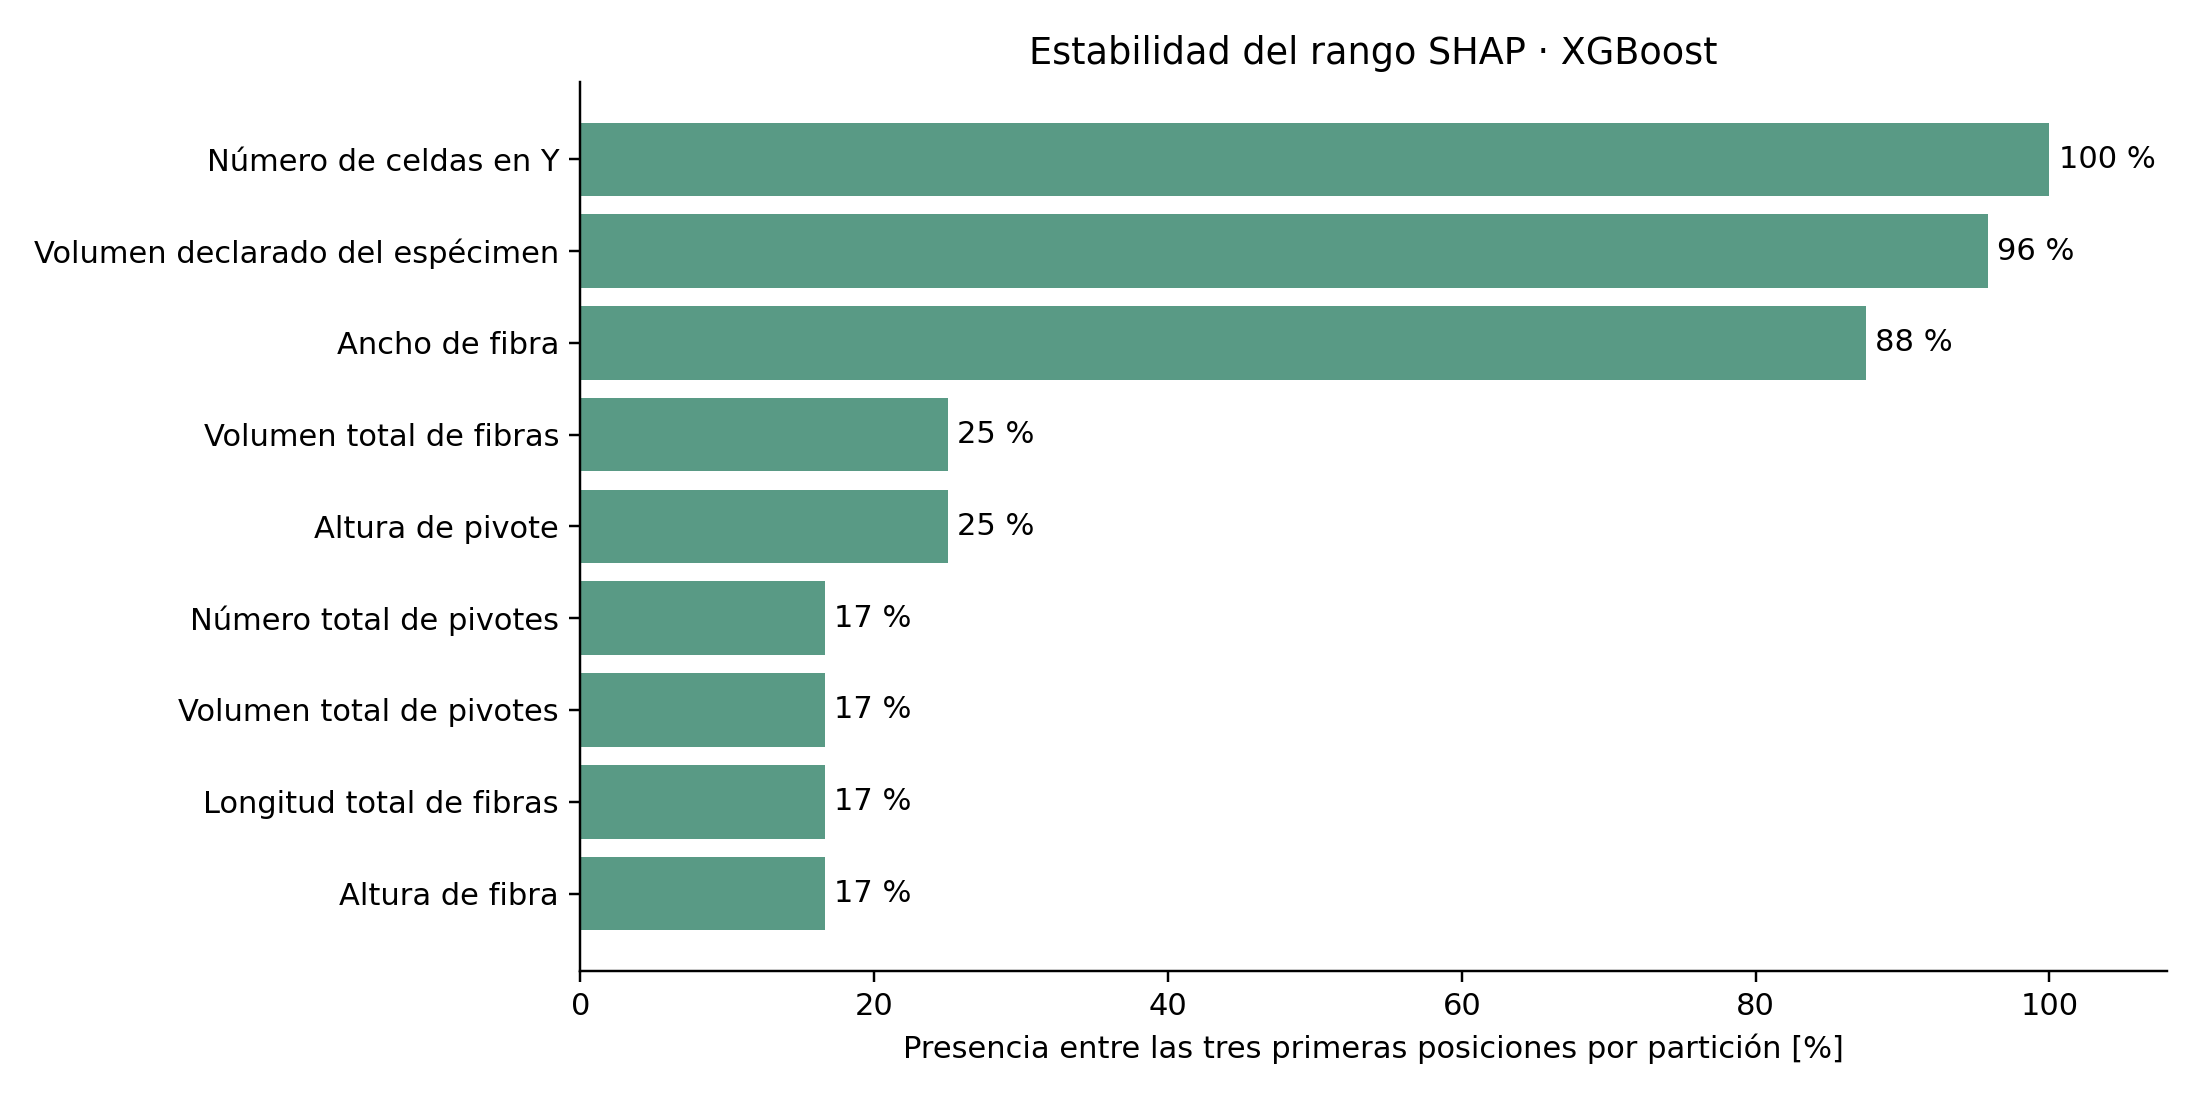

,Variable geométrica,Fracción entre las tres primeras,Rango mediano
8,Número de celdas en Y,1.000,1.0
7,Volumen declarado del espécimen,0.958,2.5
0,Ancho de fibra,0.875,3.0
4,Altura de pivote,0.250,4.0
3,Volumen total de fibras,0.250,5.0
1,Altura de fibra,0.167,6.0
2,Longitud total de fibras,0.167,6.0
6,Volumen total de pivotes,0.167,6.0
5,Número total de pivotes,0.167,6.0


In [10]:
figura(21)
caso = shap_casos.loc[shap_casos.Case_n.eq(shap_meta['caso_error_alto'])].iloc[0]
aportes = shap_oof[shap_oof.Case_n.eq(caso.Case_n)].sort_values('SHAP_N')
sube = aportes.iloc[-1]
baja = aportes.iloc[0]
interpretar(f"En el caso {int(caso.Case_n)}, el modelo estimó {caso.predicho_N:.3f} N frente a {caso.observado_N:.3f} N observados; el error firmado fue {caso.error_N:+.3f} N. "
            f"El valor de referencia fue {caso.base_SHAP_N:.3f} N. {sube.nombre} aportó {sube.SHAP_N:+.3f} N y {baja.nombre} aportó {baja.SHAP_N:+.3f} N. "
            f"La reconstrucción difiere de la predicción en {caso.error_reconstruccion_N:.2e} N. Estas contribuciones describen el comportamiento del modelo para este caso y no un mecanismo físico comprobado.", '#f3edff')
figura(22)
display(shap_estabilidad.sort_values('presencia_top3',ascending=False)
        [['nombre','presencia_top3','rango_mediano']].head(9)
        .rename(columns={'nombre':'Variable geométrica','presencia_top3':'Fracción entre las tres primeras',
                         'rango_mediano':'Rango mediano'}).round(3))
estable = shap_estabilidad.sort_values('presencia_top3',ascending=False).iloc[0]
interpretar(f"{estable.nombre} figura entre las tres primeras en {estable.presencia_top3:.1%} de las particiones. "
            'La frecuencia describe variación de rangos entre modelos entrenados; no mide incertidumbre causal ni demuestra estabilidad en otra campaña.')

## 7. Matriz de consistencia

Los objetivos expresan metas predictivas y su finalidad. Sus hipótesis pueden no quedar respaldadas por los resultados. Los cortes en cero indican la dirección del cambio de error; no establecen significancia estadística ni una tolerancia de diseño mecánico. La concordancia entre modelos es un análisis descriptivo de procedimientos dependientes.

Las mismas formulaciones se conservan en la matriz documental y en su archivo tabular.

In [11]:
matriz = pd.read_csv(ROOT/'docs/matriz_consistencia.csv')
assert matriz.notna().all().all()
vista = matriz.copy()
for col in vista:
    vista[col] = vista[col].map(lambda s: str(s).replace('; ', ';<br>').replace('**Variable dependiente:**', '<strong>Variable dependiente:</strong>').replace('**Variables independientes:**', '<strong>Variables independientes:</strong>').replace('**Bloque contrastado:**', '<strong>Bloque contrastado:</strong>'))
html = vista.to_html(index=False, escape=False, table_id='matriz', border=0)
estilo = '<style>#matriz{width:100%;table-layout:fixed;border-collapse:collapse;font-size:13px}#matriz th,#matriz td{border:0;padding:12px;vertical-align:top;text-align:left;overflow-wrap:break-word}#matriz th{background:#e4eee9}#matriz tr:nth-child(even){background:#f5f8f6}#matriz th:nth-child(1){width:17%}#matriz th:nth-child(2){width:23%}#matriz th:nth-child(3){width:20%}#matriz th:nth-child(4){width:23%}#matriz th:nth-child(5){width:17%}</style>'
display(HTML(estilo+html))
from src.revision_entrega_permutacion import evaluar_hipotesis
contrastes = evaluar_hipotesis(ROOT)
display(contrastes[['Hipótesis','Criterio','Resultado','Lectura']])

Problema de investigación,Objetivo,Hipótesis,Variables independientes y variable dependiente,Indicadores
General. ¿Puede estimarse la carga de primera falla con menor error que las referencias al reservar configuraciones geométricas?,"Alcanzar un MAE inferior al de ambas referencias al estimar la carga de primera falla con geometría previa al ensayo, para disponer de predicciones más informativas en el dominio estudiado.","HG. Al menos un modelo completo obtiene menor MAEque la mediana y la media por nivel de celdas,bajo reserva de configuraciones.","Variable dependiente: carga experimental de primera falla [N].Variables independientes:• Número de celdas en Y y número total de pivotes [conteo].• Altura, base y longitud total de fibras [mm].• Altura y radio de pivote [mm].• Volúmenes declarados de fibras, pivotes y espécimen [mm³].El radio es constante en esta campaña y se excluye al ajustar el filtro de varianza en entrenamiento.","MAE del modelo y de ambas referencias [N];diferencias y reducción relativa del MAE [%];MSE [N²], RMSE [N] y R² externos."
Específico 1. ¿Mantiene un mismo modelo su ventaja frente a ambas referencias al reservar configuraciones y familias de celdas?,"Mantener, con un mismo modelo completo, un MAE inferior al de ambas referencias en los dos protocolos, para delimitar su capacidad de estimar configuraciones y familias de celdas ausentes del entrenamiento.",H1. Un mismo modelo completo obtiene menor MAEque ambas referencias en los dos protocolos:configuraciones y familias de celdas.,"Variable dependiente: carga experimental de primera falla [N].Variables independientes:• Número de celdas en Y y número total de pivotes [conteo].• Altura, base y longitud total de fibras [mm].• Altura y radio de pivote [mm].• Volúmenes declarados de fibras, pivotes y espécimen [mm³].El radio es constante en esta campaña y se excluye al ajustar el filtro de varianza en entrenamiento.","MAE y reducción relativa frente a cada referencia, por protocolo;errores por familia reservada;MSE, RMSE y R². Deben cumplirse las cuatro comparaciones para un mismo modelo."
Específico 2. ¿Puede un mismo modelo conservar su MAE con cuatro variables seleccionadas dentro del entrenamiento?,"Conservar el MAE con cuatro variables seleccionadas internamente en al menos un mismo modelo y en ambos protocolos, para simplificar la representación geométrica sin aumentar el error observado.","H2. Al menos un mismo modelo cumple:MAE con cuatro variables ≤ MAE completo,tanto en configuraciones como en familias de celdas.","Variable dependiente: carga experimental de primera falla [N].Variables independientes:• Número de celdas en Y y número total de pivotes [conteo].• Altura, base y longitud total de fibras [mm].• Altura y radio de pivote [mm].• Volúmenes declarados de fibras, pivotes y espécimen [mm³].El radio es constante en esta campaña y se excluye al ajustar el filtro de varianza en entrenamiento.El subconjunto de cuatro variables se selecciona dentro de cada entrenamiento externo y puede cambiar entre modelos y particiones.","MAE reducido − MAE completo [N] por modelo y protocolo;MSE, RMSE y R²;frecuencia de selección y cantidad de variables seleccionadas con importancia interna no positiva."
Específico 3. ¿Depende la predicción del bloque conjunto de arquitectura y volúmenes en la mayoría de los modelos completos?,"Identificar dependencia predictiva del bloque conjunto de arquitectura y volúmenes en al menos cuatro modelos completos, para priorizar contrastes experimentales que separen la información compartida por sus componentes.","H3. Al menos cuatro de los seis modelos completos cumplensimultáneamente ΔMAE por permutación > 0y ΔMAE por ablación > 0,bajo reserva de configuraciones.","Variable dependiente: carga experimental de primera falla [N].Variables independientes:• Número de celdas en Y y número total de pivotes [conteo].• Altura, base y longitud total de fibras [mm].• Altura y radio de pivote [mm].• Volúmenes declarados de fibras, pivot

,Hipótesis,Criterio,Resultado,Lectura
0,General,Modelo completo con menor MAE que ambas refere...,Ninguno,No respaldada bajo el protocolo
1,H1,Mismo modelo completo supera ambas referencias...,Ninguno,No respaldada bajo el protocolo
2,H2,Mismo modelo reducido no incrementa MAE en amb...,"SVR RBF, Árboles extremadamente aleatorios, Gr...",Respaldada descriptivamente bajo el protocolo
3,H3,PFI y ablación positivas simultáneamente en al...,"SVR RBF, Bosque aleatorio, Árboles extremadame...",Respaldada descriptivamente bajo el protocolo


## 8. Alcance de la evidencia

La comparación separa desempeño, ajuste de hiperparámetros, selección de entradas e importancia por perturbación. Reservar familias exige transferir a un nivel arquitectónico ausente del entrenamiento; un resultado aceptable entre configuraciones no garantiza esa transferencia. El criterio de error mecánicamente tolerable y la validación en una campaña independiente siguen pendientes.

La selección interna evita usar respuestas externas para escoger columnas, pero el diseño de esta revisión se formuló después de explorar la misma campaña. Las hipótesis documentan contrastes de la actividad; no se presentan como prerregistradas ni como confirmación experimental independiente.

**Referencias metodológicas:** [importancia por permutación](https://scikit-learn.org/1.7/modules/permutation_importance.html), [limitaciones con variables correlacionadas](https://scikit-learn.org/1.7/auto_examples/inspection/plot_permutation_importance_multicollinear.html) y [validación por grupos](https://scikit-learn.org/1.7/modules/cross_validation.html#cross-validation-iterators-for-grouped-data).

La [matriz de consistencia](../docs/matriz_consistencia.md), el [protocolo y los resultados](../docs/analisis_permutacion.md) y las [tablas verificadas](../reports/modelos_no_lineales/tables/) acompañan el análisis.

In [12]:
assert not predicciones.Case_n.eq(2).any()
assert len(splits['configuracion'])==24 and len(splits['familia'])==3
print('Verificación final: respuestas observadas, particiones agrupadas y métricas coherentes.')

Verificación final: respuestas observadas, particiones agrupadas y métricas coherentes.
